# Predicting When a Person's Digital Activity Pattern Becomes Unusually Distracted
**Course:** AD23532 – Principles of Data Science · B.Tech Artificial Intelligence and Data Science · Rajalakshmi Engineering College · Semester V (2026-27 ODD)

This notebook covers the complete mini-project in the order of the three reviews:

| Review | Theme | Sections |
|---|---|---|
| Review 1 | Problem statement, dataset & project charter | 1.1 – 1.7 |
| Review 2 | Data quality, preprocessing, feature engineering & EDA | 2.1 – 2.7 |
| Review 3 | Model building, comparison, tuning & final selection | 3.1 – 3.8 |

> **Disclaimer:** the project identifies changes in usage patterns only. It does not diagnose addiction or any medical or psychological condition.

---
# REVIEW 1 — Problem Statement and Dataset Collection

## 1.1 Problem statement and background
Total screen time on its own is a weak signal: 7 hours can be a productive work day for one person and a lost day for another. What matters is **how a person's pattern changes compared with their own normal** — more social media and gaming, less productive time, much more app-switching and more late-night use.

**Problem:** given one day of a person's digital activity, predict whether that day is **Normal**, shows **Increased Distraction**, or is **Unusually Distracted**, relative to that person's own baseline.

**Why it matters:** students lose study time to fragmented app-switching; professionals see productive hours shrink before deadlines; digital-wellbeing apps only show raw hour counts. An early, personal signal lets a person act before a bad week becomes a bad month.

## 1.2 Research goal and objectives
* **Analytical objective:** multi-class **classification** (3 classes), supported by **anomaly detection** and **clustering** as unsupervised alternatives.
* O1 — build a personal baseline for every user from their own recent history.
* O2 — engineer deviation features (ratios and personal z-scores) that capture behaviour change.
* O3 — train and compare at least six approaches (statistical, unsupervised, supervised).
* O4 — select the best model with quantitative evidence and deploy it in an interactive web app.

## 1.3 Dataset collection and description
Per-app usage logs from Android *Digital Wellbeing* / iOS *Screen Time* are private and are not published as an open dataset with day-level labels. The project therefore uses a **simulated dataset** (`src/generate_dataset.py`, fixed seed 42) that reproduces the structure in the Review-1 charter and the behaviour reported in screen-time studies:

* **Size:** 40 users (22 students, 18 professionals) × 120 days (1 Jan – 29 Apr 2024) = 4,800 user-days, plus 85 duplicate syncs = **4,885 raw rows, 14 columns**.
* **Personal baselines:** each user has their own typical screen time, activity mix, switching rate and night usage.
* **Latent state:** each day follows a Markov chain over the three states (distraction persists for a few days; weekends raise the chance).
* **Real-world noise:** day-to-day variation, a weekend effect that is *not* distraction, and 7% label noise (self-reports are imperfect).
* **Injected data-quality problems** (for Review 2): missing values, duplicates, mixed date formats, inconsistent spellings, negative durations, >24 h values and a 9999 sensor glitch.

| Column | Type | Description |
|---|---|---|
| record_id | int | row id |
| user_id | categorical | anonymous user (U001–U040) |
| user_type | categorical | Student / Professional |
| date | date | day of the log |
| screen_time_hrs | float | total screen time (h) |
| social_media_min, gaming_min, productive_min, other_min | float | minutes per activity category |
| app_switches | int | number of foreground app changes |
| night_usage_min | float | usage between 23:00 and 05:00 (min) |
| phone_unlocks | int | number of unlocks |
| notifications | int | notifications received |
| **label** (target) | categorical | Normal / Increased Distraction / Unusually Distracted |

## 1.4 Project charter
* **Mission:** detect the change, understand the pattern, provide meaningful insight.
* **Stakeholders & beneficiaries:** students, working professionals, digital-wellbeing app developers, counsellors / mentors (aggregate trends only).
* **Scope:** daily-level classification from usage counts; no content of messages or apps is used. Out of scope: medical diagnosis, real-time minute-level tracking.
* **Expected outcomes:** cleaned dataset, EDA dashboard, trained and tuned classifier, deployed web app with a live predictor, technical report.

## 1.5 Proposed methodology
1. Data quality assessment → cleaning → validation.
2. EDA (univariate, bivariate, multivariate).
3. Feature engineering: activity ratios + **personal baseline z-scores** computed only from previous days (no leakage).
4. Models: Z-score statistical baseline, Isolation Forest, K-Means, Logistic Regression, Decision Tree, Random Forest.
5. Evaluation: Accuracy, Precision, Recall, F1 (macro), ROC-AUC, confusion matrix; Silhouette / Davies-Bouldin / Calinski-Harabasz for clustering.

## 1.6 Resources and feasibility
* **Software:** Python 3, pandas, NumPy, scikit-learn, SciPy, Matplotlib, Seaborn; HTML + Chart.js for the web app; Git/GitHub.
* **Hardware:** a normal laptop — the full notebook runs in under two minutes on CPU; no cloud GPU needed.
* **Related work:** smartphone-usage studies link frequent app switching and late-night use to self-reported distraction; anomaly-detection literature recommends *person-specific* baselines over population thresholds for behavioural data.
* **Feasibility:** high — small tabular data, standard libraries, 6-week plan below.

## 1.7 Timeline (6 weeks)
| Week | Milestone | Output |
|---|---|---|
| 1 | Environment setup & literature review | charter (Review 1) |
| 2 | Data collection & logging | raw dataset |
| 3 | Cleaning & preprocessing | clean dataset |
| 4 | EDA & feature engineering | EDA report (Review 2) |
| 5 | Baseline & ML modelling, tuning | model comparison |
| 6 | Evaluation, web app, final report | deployed app + report (Review 3) |

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, calinski_harabasz_score, confusion_matrix, davies_bouldin_score,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve, silhouette_score,
                             classification_report)
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140, "display.max_columns", 30)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 90, "axes.titleweight": "bold"})

DATA, FIG, MODELS, APP = Path("../data"), Path("../figures"), Path("../models"), Path("../app")
for p in (FIG, MODELS, APP):
    p.mkdir(exist_ok=True)
CLASSES = ["Normal", "Increased Distraction", "Unusually Distracted"]
COLORS = {"Normal": "#2a9d8f", "Increased Distraction": "#e9c46a", "Unusually Distracted": "#e76f51"}
RANDOM_STATE = 42


def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")


print("Libraries loaded")

Libraries loaded


---
# REVIEW 2 — Data Preprocessing and Exploratory Data Analysis
## 2.1 Data quality assessment

In [2]:
raw = pd.read_csv(DATA / "raw_digital_activity.csv")
print("Shape:", raw.shape)
raw.head(8)

Shape: (4885, 14)


,record_id,user_id,user_type,date,screen_time_hrs,social_media_min,gaming_min,productive_min,other_min,app_switches,night_usage_min,phone_unlocks,notifications,label
0,1,U010,Student,2024-03-10,5.89,189.7,16.7,87.4,59.4,42,12.1,48.0,156.0,Normal
1,2,U004,Student,2024-02-03,5.51,150.0,85.4,48.1,47.0,61,60.6,63.0,75.0,Increased Distraction
2,3,U011,STUDENT,2024-03-09,9.69,124.9,114.8,138.6,203.4,61,29.7,51.0,76.0,Normal
3,4,U036,Professional,2024-02-02,4.39,119.9,37.2,50.9,55.4,116,7.2,91.0,254.0,Unusually Distracted
4,5,U015,Student,2024-04-16,5.75,63.5,45.7,106.5,129.4,61,19.1,50.0,75.0,Increased Distraction
5,6,U035,Professional,2024-03-30,5.04,39.0,4.9,178.7,80.0,55,16.3,75.0,110.0,Normal
6,7,U020,Student,2024-02-06,6.14,95.1,85.9,89.2,98.3,56,42.6,58.0,124.0,INCREASED DISTRACTION
7,8,U030,Professional,2024-04-21,10.21,311.2,NaN,29.6,22.4,170,61.5,192.0,262.0,Unusually Distracted


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 4885 entries, 0 to 4884
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   record_id         4885 non-null   int64  
 1   user_id           4885 non-null   str    
 2   user_type         4834 non-null   str    
 3   date              4885 non-null   str    
 4   screen_time_hrs   4885 non-null   float64
 5   social_media_min  4762 non-null   float64
 6   gaming_min        4789 non-null   float64
 7   productive_min    4885 non-null   float64
 8   other_min         4885 non-null   float64
 9   app_switches      4885 non-null   int64  
 10  night_usage_min   4740 non-null   float64
 11  phone_unlocks     4788 non-null   float64
 12  notifications     4688 non-null   float64
 13  label             4885 non-null   str    
dtypes: float64(8), int64(2), str(4)
memory usage: 534.4 KB


In [4]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
record_id,4885.0,2443.00,1410.32,1.00,1222.0,2443.00,3664.00,4885.00
screen_time_hrs,4885.0,5.32,1.94,1.63,4.1,5.14,6.25,29.85
social_media_min,4762.0,92.82,78.01,7.60,40.5,68.00,122.40,690.10
gaming_min,4789.0,49.96,49.36,-35.00,15.1,30.50,72.90,508.90
productive_min,4885.0,85.95,51.40,4.30,48.5,76.40,113.70,338.60
other_min,4885.0,87.85,47.28,11.40,53.3,80.30,113.60,361.80
app_switches,4885.0,99.87,531.59,22.00,51.0,65.00,84.00,9999.00
night_usage_min,4740.0,31.31,58.60,1.80,16.3,24.50,36.60,1379.50
phone_unlocks,4788.0,81.49,32.51,22.00,60.0,75.00,96.00,333.00
notifications,4688.0,111.08,43.54,23.00,78.0,108.00,138.00,317.00


In [5]:
# ---------- Systematic data-quality audit ----------
num_cols = ["screen_time_hrs", "social_media_min", "gaming_min", "productive_min", "other_min",
            "app_switches", "night_usage_min", "phone_unlocks", "notifications"]

issues = []
# 1. missing values
for c, n in raw.isna().sum().items():
    if n:
        issues.append(("Missing values", c, n))
# 2. duplicates (all columns except record_id)
dup_full = raw.duplicated(subset=raw.columns.drop("record_id")).sum()
issues.append(("Exact duplicate records", "all columns", dup_full))
# 3. inconsistent category spellings
issues.append(("Inconsistent label spellings", "label", (~raw["label"].isin(CLASSES)).sum()))
issues.append(("Inconsistent user_type spellings", "user_type",
               (~raw["user_type"].isin(["Student", "Professional"]) & raw["user_type"].notna()).sum()))
# 4. mixed date formats
issues.append(("Non-ISO date format (dd/mm/yyyy)", "date", raw["date"].str.contains("/").sum()))
# 5. invalid / impossible values
issues.append(("Negative duration", "gaming_min", (raw["gaming_min"] < 0).sum()))
issues.append(("Screen time > 24 h", "screen_time_hrs", (raw["screen_time_hrs"] > 24).sum()))
issues.append(("Night usage > 6 h window (360 min)", "night_usage_min", (raw["night_usage_min"] > 360).sum()))
issues.append(("Sensor glitch value 9999", "app_switches", (raw["app_switches"] == 9999).sum()))
# 6. internal inconsistency: components do not add up to total screen time
comp = raw[["social_media_min", "gaming_min", "productive_min", "other_min"]].sum(axis=1, min_count=4) / 60
issues.append(("Total ≠ sum of activity minutes (>0.1 h)", "screen_time_hrs",
               ((comp - raw["screen_time_hrs"]).abs() > 0.1).sum()))

issue_table = pd.DataFrame(issues, columns=["Issue", "Column", "Rows affected"])
issue_table["% of rows"] = (issue_table["Rows affected"] / len(raw) * 100).round(2)
issue_table

,Issue,Column,Rows affected,% of rows
0,Missing values,user_type,51,1.04
1,Missing values,social_media_min,123,2.52
2,Missing values,gaming_min,96,1.97
3,Missing values,night_usage_min,145,2.97
4,Missing values,phone_unlocks,97,1.99
5,Missing values,notifications,197,4.03
6,Exact duplicate records,all columns,85,1.74
7,Inconsistent label spellings,label,290,5.94
8,Inconsistent user_type spellings,user_type,190,3.89
9,Non-ISO date format (dd/mm/yyyy),date,242,4.95


In [6]:
# Outlier detection (IQR rule) on the raw numeric columns – before any cleaning
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outlier_table = pd.DataFrame({c: {"IQR outliers": iqr_outliers(raw[c].dropna()),
                                  "skewness": round(raw[c].skew(), 2)} for c in num_cols}).T
outlier_table

,IQR outliers,skewness
screen_time_hrs,117.0,2.95
social_media_min,247.0,2.19
gaming_min,191.0,1.85
productive_min,130.0,1.05
other_min,113.0,1.02
app_switches,232.0,18.52
night_usage_min,237.0,18.58
phone_unlocks,184.0,1.64
notifications,49.0,0.64


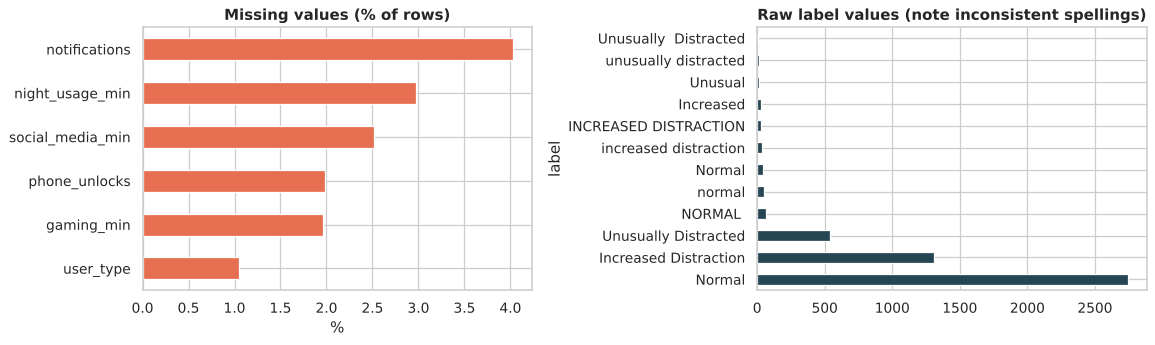

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
miss = raw.isna().mean().mul(100).sort_values()
miss[miss > 0].plot.barh(ax=ax[0], color="#e76f51")
ax[0].set_title("Missing values (% of rows)"); ax[0].set_xlabel("%")
raw["label"].value_counts().plot.barh(ax=ax[1], color="#264653")
ax[1].set_title("Raw label values (note inconsistent spellings)")
plt.tight_layout(); savefig("01_data_quality")

**Documented issues.** The audit finds six families of problems: (1) missing values in six columns (1–4%), (2) 85 duplicate syncs, (3) inconsistent spellings in `label` and `user_type`, (4) ~5% of dates in `dd/mm/yyyy`, (5) impossible values — negative gaming minutes, screen time above 24 h, night usage longer than the night window, and the `9999` overflow in app switches, and (6) totals that no longer match the activity breakdown because of those errors. Most IQR "outliers" in social, gaming and night usage are **real distracted days** — they are the signal we want to predict, so they must not be blindly removed.

## 2.2 Data preprocessing and cleansing

In [8]:
df = raw.copy()
log = []

# 1. Standardise text categories
label_map = {"normal": "Normal", "increased": "Increased Distraction", "increased distraction": "Increased Distraction",
             "unusual": "Unusually Distracted", "unusually distracted": "Unusually Distracted"}
df["label"] = df["label"].str.strip().str.lower().str.replace(r"\s+", " ", regex=True).map(label_map)
df["user_type"] = df["user_type"].str.strip().str.title()
log.append(("Standardised label / user_type spellings", int((~raw['label'].isin(CLASSES)).sum())))

# 2. Parse both date formats into one datetime column
iso = pd.to_datetime(df["date"], format="%Y-%m-%d", errors="coerce")
dmy = pd.to_datetime(df["date"], format="%d/%m/%Y", errors="coerce")
df["date"] = iso.fillna(dmy)
assert df["date"].notna().all()
log.append(("Unified dd/mm/yyyy dates to ISO", int(raw['date'].str.contains('/').sum())))

# 3. Remove duplicates: exact copies first, then any remaining same user + same day
before = len(df)
df = df.drop_duplicates(subset=df.columns.drop("record_id"))
df = df.sort_values("record_id").drop_duplicates(subset=["user_id", "date"], keep="first")
log.append(("Removed duplicate user-day records", before - len(df)))

# 4. Invalid values -> NaN (they are measurement errors, not behaviour)
inval = {
    "gaming_min": df["gaming_min"] < 0,
    "app_switches": df["app_switches"] == 9999,
    "night_usage_min": df["night_usage_min"] > 360,
}
for c, m in inval.items():
    df.loc[m, c] = np.nan
    log.append((f"Invalid {c} set to missing", int(m.sum())))

# 5. user_type is constant per user -> fill from the user's other rows
df["user_type"] = df.groupby("user_id")["user_type"].transform(lambda s: s.fillna(s.mode().iloc[0]))

# 6. Numeric missing values -> the user's own median (personal, robust to outliers)
fill_cols = ["social_media_min", "gaming_min", "night_usage_min", "app_switches", "phone_unlocks", "notifications"]
n_missing = int(df[fill_cols].isna().sum().sum())
df[fill_cols] = df.groupby("user_id")[fill_cols].transform(lambda s: s.fillna(s.median()))
log.append(("Imputed numeric gaps with the user's own median", n_missing))

# 7. Re-derive total screen time from its components (fixes > 24 h and mismatches)
recomputed = df[["social_media_min", "gaming_min", "productive_min", "other_min"]].sum(axis=1) / 60
fixed = int(((recomputed - df["screen_time_hrs"]).abs() > 0.1).sum())
df["screen_time_hrs"] = recomputed.round(2)
log.append(("Recomputed screen_time_hrs from activity minutes", fixed))

df[["app_switches", "phone_unlocks", "notifications"]] = df[["app_switches", "phone_unlocks", "notifications"]].round().astype(int)
df = df.sort_values(["user_id", "date"]).reset_index(drop=True)
pd.DataFrame(log, columns=["Cleaning step", "Rows affected"])

,Cleaning step,Rows affected
0,Standardised label / user_type spellings,290
1,Unified dd/mm/yyyy dates to ISO,242
2,Removed duplicate user-day records,85
3,Invalid gaming_min set to missing,12
4,Invalid app_switches set to missing,14
5,Invalid night_usage_min set to missing,10
6,Imputed numeric gaps with the user's own median,682
7,Recomputed screen_time_hrs from activity minutes,153


In [9]:
# ---------- Validation: the cleaned data must satisfy every rule ----------
checks = {
    "no missing values": df.isna().sum().sum() == 0,
    "one row per user per day": not df.duplicated(["user_id", "date"]).any(),
    "40 users x 120 days": len(df) == 40 * 120,
    "labels in the 3 valid classes": df["label"].isin(CLASSES).all(),
    "user_type valid": df["user_type"].isin(["Student", "Professional"]).all(),
    "all durations >= 0": (df[num_cols] >= 0).all().all(),
    "screen time <= 24 h": (df["screen_time_hrs"] <= 24).all(),
    "night usage <= 360 min": (df["night_usage_min"] <= 360).all(),
}
for k, v in checks.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")
assert all(checks.values())
print("\nClean shape:", df.shape)
df.to_csv(DATA / "clean_digital_activity.csv", index=False)

PASS  no missing values
PASS  one row per user per day
PASS  40 users x 120 days
PASS  labels in the 3 valid classes
PASS  user_type valid
PASS  all durations >= 0
PASS  screen time <= 24 h
PASS  night usage <= 360 min

Clean shape: (4800, 14)


**Justification of the techniques.**
* *Text standardisation* and *two-format date parsing* recover rows instead of dropping them.
* *Duplicates* are removed on the natural key (user + date) because one person can only have one log per day.
* *Impossible values are converted to missing* rather than clipped — clipping a 9999 to a maximum would invent a fake extreme day.
* *Per-user median imputation* respects personal baselines (a population mean would pull heavy users down and light users up) and the median is robust to the skewed distributions found above.
* *Screen time is recomputed* from its components, so totals are internally consistent.
* *Genuine high values are kept*: the IQR outliers are mostly distracted days — the very events we want to detect.

## 2.3 Data transformation and feature engineering

In [10]:
df["day_of_week"] = df["date"].dt.dayofweek
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)
df["is_student"] = (df["user_type"] == "Student").astype(int)          # binary encoding of user_type
df["label_code"] = df["label"].map({c: i for i, c in enumerate(CLASSES)})  # ordinal encoding of target

# --- Ratio features from the Review-1 charter ---
total_min = df["screen_time_hrs"] * 60
df["distraction_ratio"] = (df["social_media_min"] + df["gaming_min"]) / total_min
df["productive_ratio"] = df["productive_min"] / total_min
df["switch_rate_per_hr"] = df["app_switches"] / df["screen_time_hrs"]
df["night_usage_ratio"] = df["night_usage_min"] / total_min
df["unlocks_per_hr"] = df["phone_unlocks"] / df["screen_time_hrs"]

# --- Personal baseline: mean and std of the user's PREVIOUS 14 days (shift(1) => no look-ahead leakage) ---
BASE_COLS = ["screen_time_hrs", "social_media_min", "gaming_min", "productive_min",
             "app_switches", "night_usage_min", "phone_unlocks", "distraction_ratio", "productive_ratio"]
WINDOW, MIN_DAYS = 14, 7
g = df.groupby("user_id")
for c in BASE_COLS:
    prev = g[c].shift(1)
    mu = prev.groupby(df["user_id"]).transform(lambda s: s.rolling(WINDOW, min_periods=MIN_DAYS).mean())
    sd = prev.groupby(df["user_id"]).transform(lambda s: s.rolling(WINDOW, min_periods=MIN_DAYS).std())
    sd = sd.clip(lower=0.10 * mu.abs() + 1e-6)  # floor so a very stable fortnight does not explode z-scores
    df[f"z_{c}"] = (df[c] - mu) / sd

# Composite deviation score: average signed deviation in the "distracted" direction
df["deviation_score"] = (df["z_social_media_min"] + df["z_gaming_min"] + df["z_app_switches"]
                         + df["z_night_usage_min"] - df["z_productive_min"]) / 5

# The first 7 days of every user have no baseline yet (warm-up period)
feat = df.dropna(subset=[f"z_{c}" for c in BASE_COLS]).reset_index(drop=True)
print(f"Rows after baseline warm-up: {len(feat)} (dropped {len(df) - len(feat)} warm-up days)")
feat[["user_id", "date", "app_switches", "z_app_switches", "distraction_ratio", "deviation_score", "label"]].head()

Rows after baseline warm-up: 4520 (dropped 280 warm-up days)


,user_id,date,app_switches,z_app_switches,distraction_ratio,deviation_score,label
0,U001,2024-01-08,38,-0.364647,0.488189,-0.616100,Normal
1,U001,2024-01-09,40,-0.204803,0.624694,-0.318870,Normal
2,U001,2024-01-10,39,-0.266887,0.436059,-1.244006,Normal
3,U001,2024-01-11,32,-0.792021,0.523250,0.000177,Normal
4,U001,2024-01-12,34,-0.578802,0.566340,-0.450550,Normal


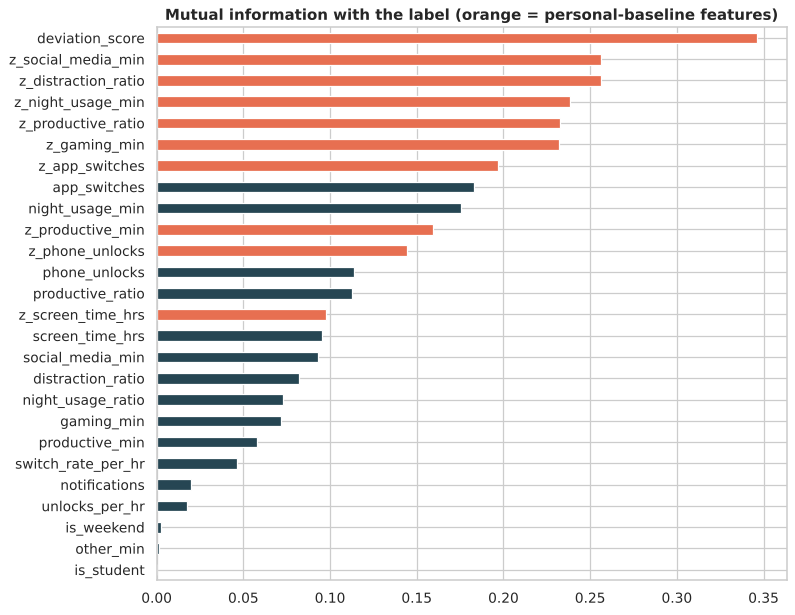

,deviation_score,z_social_media_min,z_distraction_ratio,z_night_usage_min,z_productive_ratio,z_gaming_min,z_app_switches,app_switches,night_usage_min,z_productive_min,z_phone_unlocks,phone_unlocks,productive_ratio,z_screen_time_hrs,screen_time_hrs,social_media_min,distraction_ratio,night_usage_ratio,gaming_min,productive_min,switch_rate_per_hr,notifications,unlocks_per_hr,is_weekend,other_min,is_student
mutual_info,0.346,0.256,0.256,0.238,0.232,0.232,0.197,0.183,0.176,0.16,0.145,0.114,0.113,0.098,0.095,0.093,0.082,0.073,0.072,0.058,0.046,0.02,0.017,0.003,0.002,0.0


In [11]:
# Feature selection: mutual information with the label + redundancy check
RAW_FEATURES = ["screen_time_hrs", "social_media_min", "gaming_min", "productive_min", "other_min", "app_switches",
                "night_usage_min", "phone_unlocks", "notifications", "is_weekend", "is_student"]
RATIO_FEATURES = ["distraction_ratio", "productive_ratio", "switch_rate_per_hr", "night_usage_ratio", "unlocks_per_hr"]
Z_FEATURES = [f"z_{c}" for c in BASE_COLS] + ["deviation_score"]
CANDIDATES = RAW_FEATURES + RATIO_FEATURES + Z_FEATURES

mi = pd.Series(mutual_info_classif(feat[CANDIDATES], feat["label_code"], random_state=RANDOM_STATE),
               index=CANDIDATES).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 7))
mi.plot.barh(ax=ax, color=["#e76f51" if i.startswith(("z_", "dev")) else "#264653" for i in mi.index])
ax.invert_yaxis(); ax.set_title("Mutual information with the label (orange = personal-baseline features)")
plt.tight_layout(); savefig("02_mutual_information")
mi.round(3).to_frame("mutual_info").T

In [12]:
# Remove near-redundant features (|r| > 0.9), keeping the one with higher mutual information
corr = feat[CANDIDATES].corr().abs()
drop = set()
for a in mi.index:
    for b in mi.index:
        if a != b and a not in drop and b not in drop and corr.loc[a, b] > 0.9 and mi[a] >= mi[b]:
            drop.add(b)
# features with near-zero mutual information (MI < 0.005) add only noise -> drop
drop |= {c for c in CANDIDATES if mi[c] < 0.005}
FEATURES = [c for c in CANDIDATES if c not in drop]
print("Dropped:", sorted(drop))
print(f"Selected {len(FEATURES)} features:", FEATURES)

Dropped: ['is_student', 'is_weekend', 'other_min']
Selected 23 features: ['screen_time_hrs', 'social_media_min', 'gaming_min', 'productive_min', 'app_switches', 'night_usage_min', 'phone_unlocks', 'notifications', 'distraction_ratio', 'productive_ratio', 'switch_rate_per_hr', 'night_usage_ratio', 'unlocks_per_hr', 'z_screen_time_hrs', 'z_social_media_min', 'z_gaming_min', 'z_productive_min', 'z_app_switches', 'z_night_usage_min', 'z_phone_unlocks', 'z_distraction_ratio', 'z_productive_ratio', 'deviation_score']


**Transformations applied.** `user_type` → binary `is_student`; target → ordinal `label_code` (0/1/2); date → `day_of_week`, `is_weekend`. Four charter ratios (+ unlocks per hour) normalise for total usage. **Personal z-scores** compare each day with the same person's previous 14 days, using only past data so that no future information leaks into training. Standard scaling is applied inside each model pipeline (fitted on training data only) for the distance/linear models; tree models do not need it. Feature selection uses mutual information and drops highly correlated duplicates.

## 2.4 Data integration — user profile table, subsets and aggregated views

In [13]:
# Build a user-level profile table and merge it back (integration of two granularities)
profile = (df.groupby("user_id")
             .agg(user_type=("user_type", "first"), avg_screen_hrs=("screen_time_hrs", "mean"),
                  avg_switches=("app_switches", "mean"), avg_night_min=("night_usage_min", "mean"),
                  pct_distracted_days=("label_code", lambda s: (s > 0).mean() * 100))
             .round(2).reset_index())
feat = feat.merge(profile[["user_id", "avg_screen_hrs"]].rename(columns={"avg_screen_hrs": "user_avg_screen_hrs"}),
                  on="user_id", how="left")
print("Profile table:", profile.shape)
display(profile.head())

# Subsets / views for specific analysis
views = {"Students": feat[feat.user_type == "Student"], "Professionals": feat[feat.user_type == "Professional"],
         "Weekdays": feat[feat.is_weekend == 0], "Weekends": feat[feat.is_weekend == 1]}
pd.DataFrame({k: v["label"].value_counts(normalize=True).reindex(CLASSES).mul(100).round(1)
              for k, v in views.items()}).T.assign(rows=[len(v) for v in views.values()])

Profile table: (40, 6)


,user_id,user_type,avg_screen_hrs,avg_switches,avg_night_min,pct_distracted_days
0,U001,Student,6.28,56.38,51.20,43.33
1,U002,Student,5.67,61.68,26.87,32.50
2,U003,Student,6.42,55.55,24.65,35.83
3,U004,Student,4.17,70.24,38.45,43.33
4,U005,Student,5.01,78.77,44.24,37.50


label,Normal,Increased Distraction,Unusually Distracted,rows
Students,58.2,30.1,11.7,2486
Professionals,60.6,27.1,12.3,2034
Weekdays,62.3,27.1,10.7,3240
Weekends,51.7,33.0,15.2,1280


**Integration strategy.** The daily log (4,800 rows) and a derived user profile table (40 rows) are joined on `user_id` with a left join, so every day carries its user's context without losing any day. The weekly reshape below (pivot by day of week) and the subset views are used in EDA. `user_avg_screen_hrs` is used only for analysis, not as a model feature, because it is computed over the full period.

## 2.5 Exploratory data analysis
### Univariate analysis

In [14]:
print("Descriptive statistics of the cleaned data")
desc = df[num_cols].describe().T
desc["skew"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurtosis()
desc.round(2)

Descriptive statistics of the cleaned data


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
screen_time_hrs,4800.0,5.27,1.71,1.63,4.10,5.14,6.23,14.94,0.84,1.57
social_media_min,4800.0,92.63,77.48,7.60,40.40,68.20,122.90,690.10,2.19,7.22
gaming_min,4800.0,50.17,49.17,0.40,15.20,30.65,73.40,508.90,1.86,5.12
productive_min,4800.0,85.73,51.27,4.30,48.48,76.35,113.12,338.60,1.06,1.36
other_min,4800.0,87.93,47.37,11.40,53.30,80.40,113.70,361.80,1.02,1.35
app_switches,4800.0,71.44,29.76,22.00,51.00,65.00,84.00,291.00,1.70,4.75
night_usage_min,4800.0,28.69,19.62,1.80,16.40,24.40,36.50,216.80,1.97,7.69
phone_unlocks,4800.0,81.40,32.36,22.00,60.00,75.00,96.00,333.00,1.65,5.11
notifications,4800.0,110.85,43.07,23.00,78.00,108.00,138.00,317.00,0.63,0.59


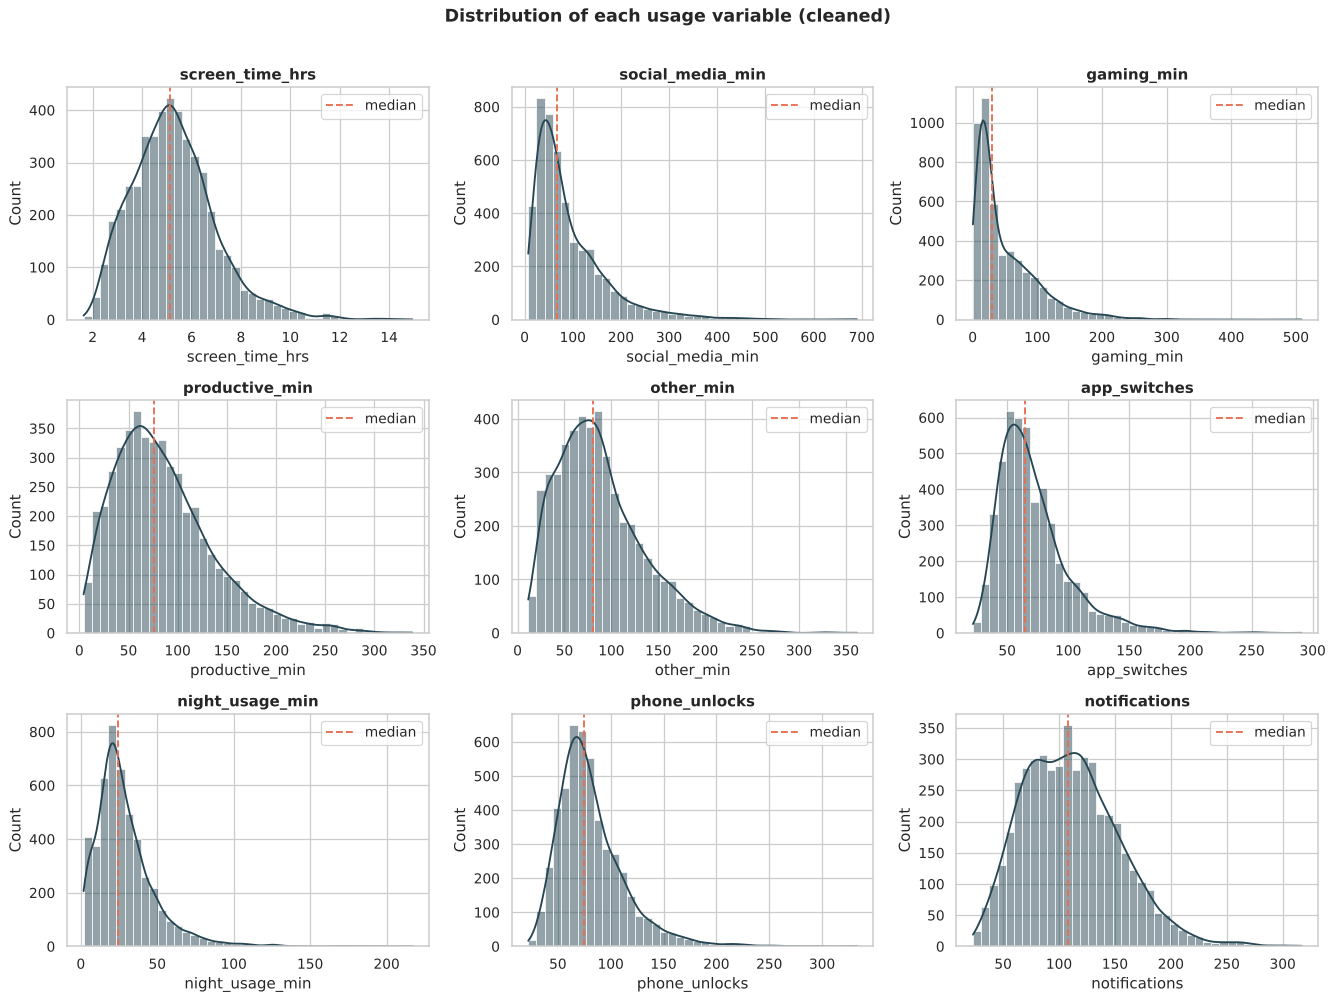

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], bins=40, kde=True, ax=ax, color="#264653")
    ax.axvline(df[c].median(), color="#e76f51", ls="--", lw=1.5, label="median")
    ax.set_title(c); ax.legend()
plt.suptitle("Distribution of each usage variable (cleaned)", y=1.01, fontsize=14, weight="bold")
plt.tight_layout(); savefig("03_histograms")

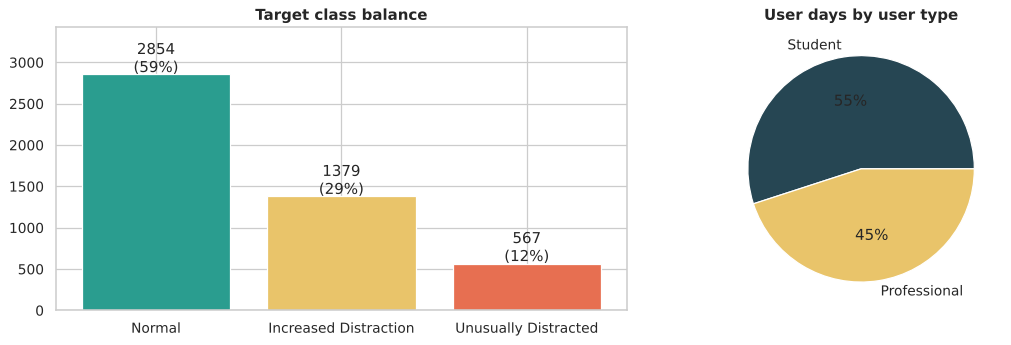

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
vc = df["label"].value_counts().reindex(CLASSES)
ax[0].bar(vc.index, vc.values, color=[COLORS[c] for c in CLASSES])
for i, v in enumerate(vc.values):
    ax[0].text(i, v + 30, f"{v}\n({v / len(df):.0%})", ha="center")
ax[0].set_title("Target class balance"); ax[0].set_ylim(0, vc.max() * 1.2)
df["user_type"].value_counts().plot.pie(ax=ax[1], autopct="%1.0f%%", colors=["#264653", "#e9c46a"], ylabel="")
ax[1].set_title("User days by user type")
plt.tight_layout(); savefig("04_class_balance")

### Bivariate analysis

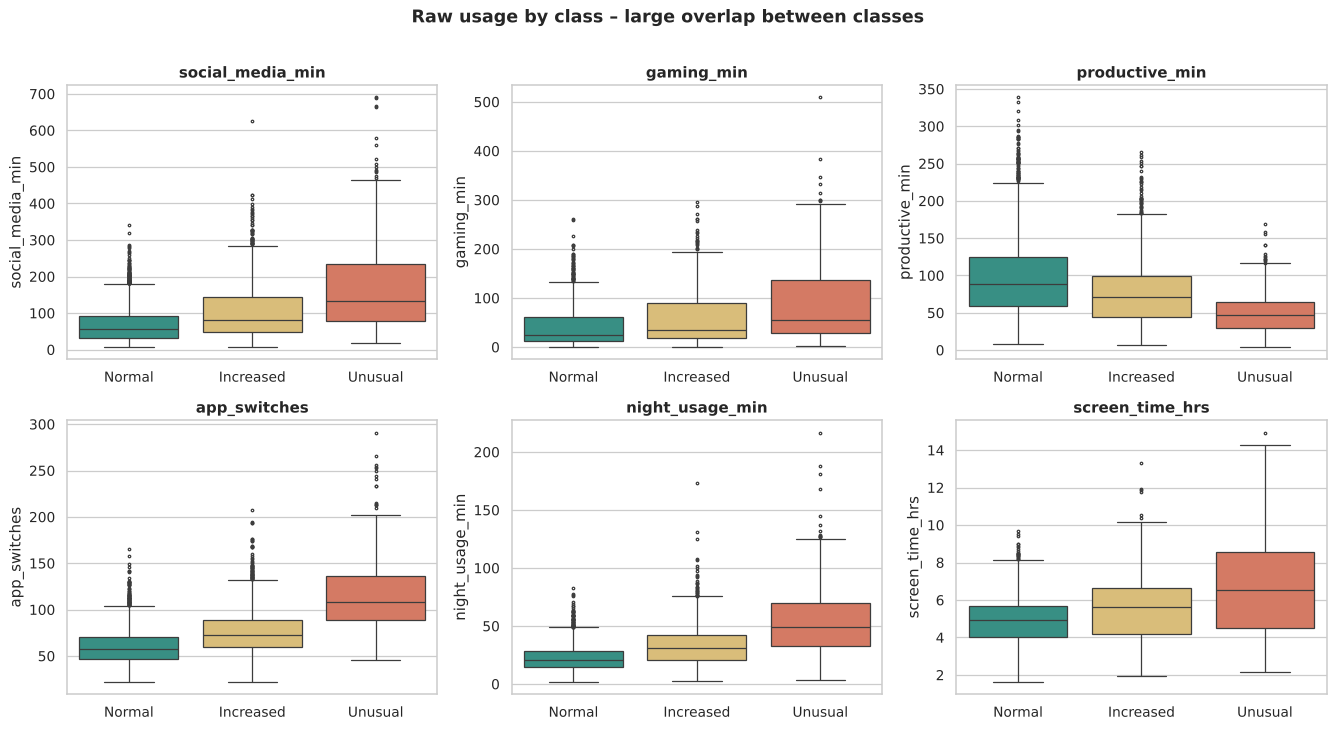

In [17]:
show = ["social_media_min", "gaming_min", "productive_min", "app_switches", "night_usage_min", "screen_time_hrs"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), show):
    sns.boxplot(data=df, x="label", y=c, order=CLASSES, palette=COLORS, ax=ax, fliersize=2)
    ax.set_xticklabels(["Normal", "Increased", "Unusual"]); ax.set_xlabel(""); ax.set_title(c)
plt.suptitle("Raw usage by class – large overlap between classes", y=1.01, fontsize=14, weight="bold")
plt.tight_layout(); savefig("05_boxplots_raw")

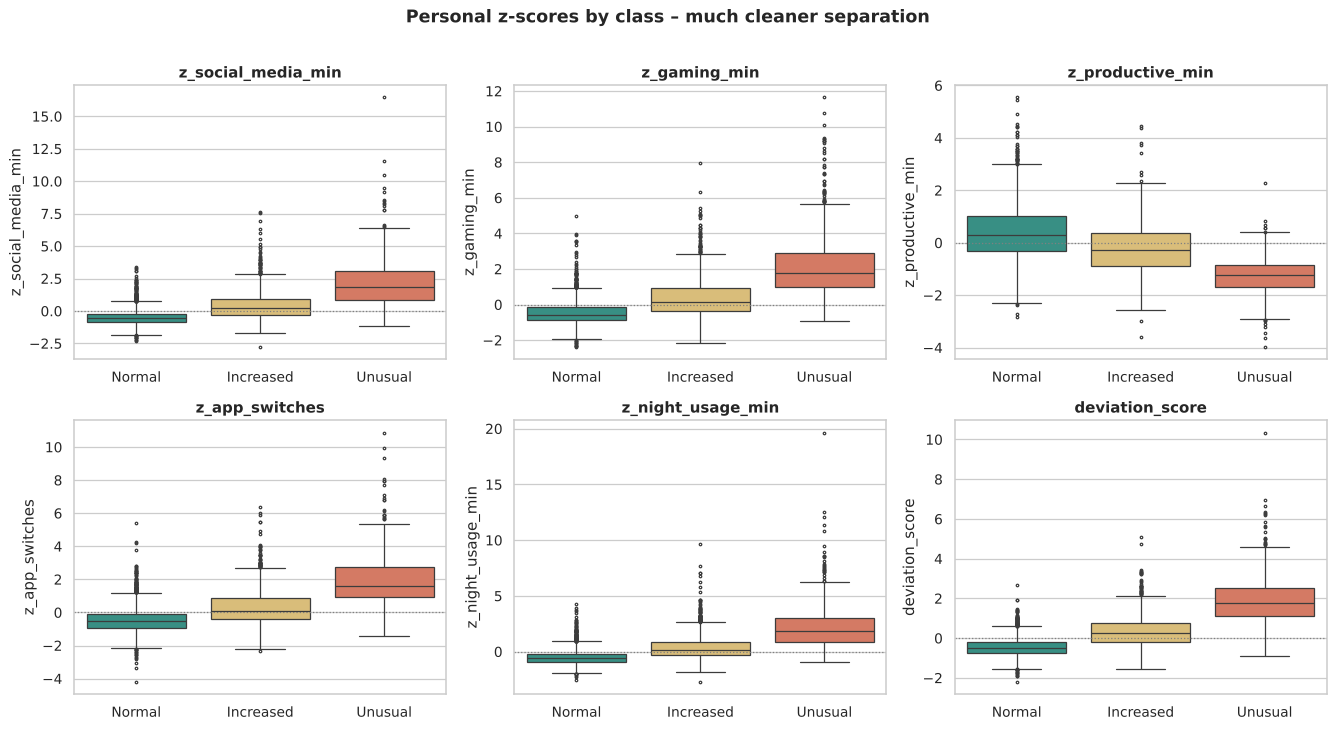

In [18]:
show_z = ["z_social_media_min", "z_gaming_min", "z_productive_min", "z_app_switches", "z_night_usage_min", "deviation_score"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), show_z):
    sns.boxplot(data=feat, x="label", y=c, order=CLASSES, palette=COLORS, ax=ax, fliersize=2)
    ax.axhline(0, color="grey", lw=1, ls=":")
    ax.set_xticklabels(["Normal", "Increased", "Unusual"]); ax.set_xlabel(""); ax.set_title(c)
plt.suptitle("Personal z-scores by class – much cleaner separation", y=1.01, fontsize=14, weight="bold")
plt.tight_layout(); savefig("06_boxplots_z")

In [19]:
# Statistical test: does each feature differ across the three classes? (Kruskal-Wallis, non-parametric)
rows = []
for c in ["screen_time_hrs", "app_switches", "night_usage_min", "distraction_ratio", "z_app_switches", "deviation_score"]:
    h, p = stats.kruskal(*[feat.loc[feat.label == k, c] for k in CLASSES])
    eps2 = h / (len(feat) - 1)  # epsilon-squared effect size
    rows.append((c, round(h, 1), f"{p:.1e}", round(eps2, 3)))
pd.DataFrame(rows, columns=["feature", "H statistic", "p-value", "effect size ε²"])

,feature,H statistic,p-value,effect size ε²
0,screen_time_hrs,319.3,4.6e-70,0.071
1,app_switches,1340.6,7.9e-292,0.297
2,night_usage_min,869.9,1.2e-189,0.193
3,distraction_ratio,580.1,1.1e-126,0.128
4,z_app_switches,1400.9,6.3e-305,0.310
5,deviation_score,2080.6,0.0e+00,0.460


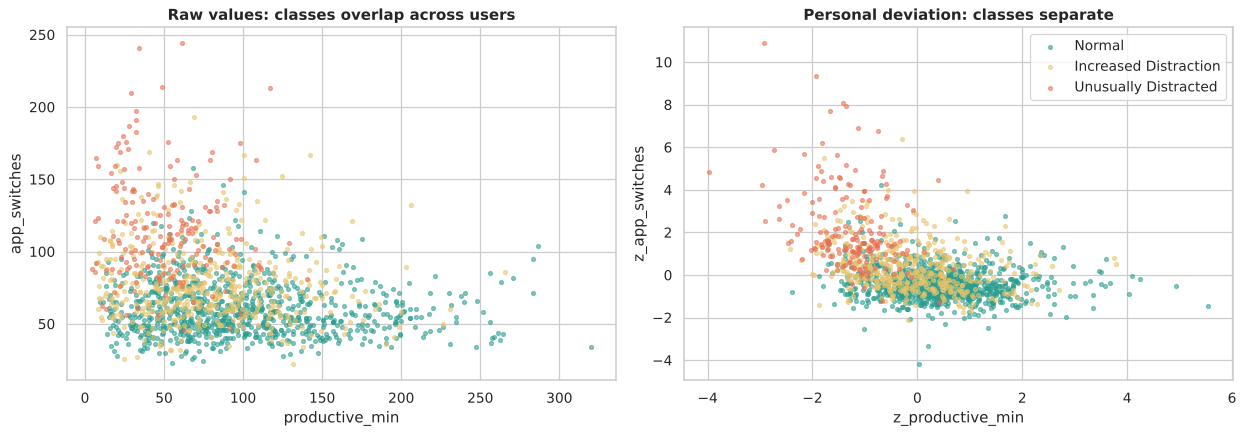

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sample = feat.sample(1500, random_state=RANDOM_STATE)
for c in CLASSES:
    s = sample[sample.label == c]
    ax[0].scatter(s["productive_min"], s["app_switches"], s=10, alpha=.55, color=COLORS[c], label=c)
    ax[1].scatter(s["z_productive_min"], s["z_app_switches"], s=10, alpha=.55, color=COLORS[c], label=c)
ax[0].set(xlabel="productive_min", ylabel="app_switches", title="Raw values: classes overlap across users")
ax[1].set(xlabel="z_productive_min", ylabel="z_app_switches", title="Personal deviation: classes separate")
ax[1].legend(); plt.tight_layout(); savefig("07_scatter_raw_vs_z")

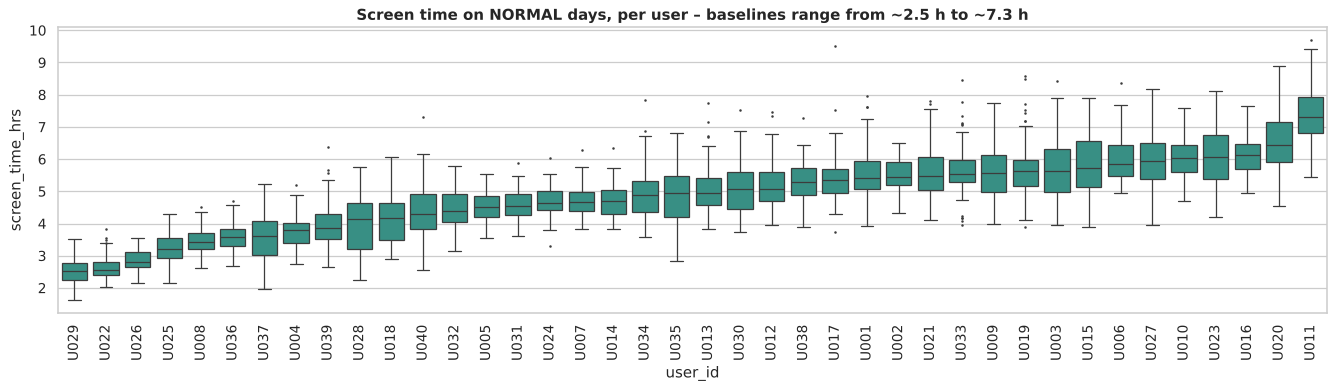

In [21]:
# Personal baselines differ a lot: the same 6 h of screen time is "normal" for one user and unusual for another
normal_days = df[df.label == "Normal"]
order = normal_days.groupby("user_id")["screen_time_hrs"].median().sort_values().index
fig, ax = plt.subplots(figsize=(15, 4.5))
sns.boxplot(data=normal_days, x="user_id", y="screen_time_hrs", order=order, color="#2a9d8f", ax=ax, fliersize=1)
ax.set_title("Screen time on NORMAL days, per user – baselines range from ~2.5 h to ~7.3 h")
ax.tick_params(axis="x", rotation=90); plt.tight_layout(); savefig("08_personal_baselines")

### Trends over time and by day of week (reshaped data)

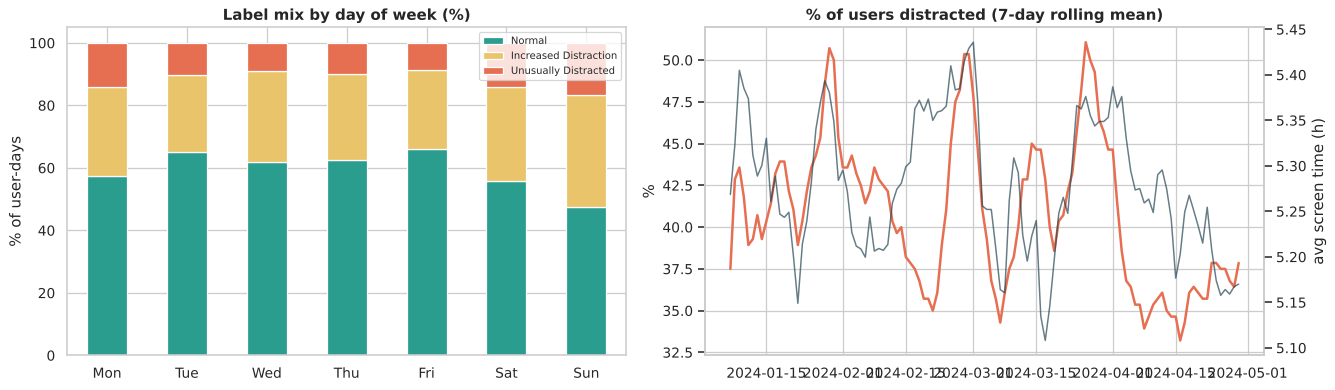

label,Normal,Increased Distraction,Unusually Distracted
dow,,,
Mon,57.4,28.6,14.0
Tue,65.0,24.9,10.1
Wed,61.9,29.0,9.1
Thu,62.6,27.5,9.9
Fri,66.0,25.3,8.7
Sat,55.9,30.1,14.0
Sun,47.5,35.7,16.8


In [22]:
weekly = (df.assign(dow=df["date"].dt.day_name().str[:3])
            .pivot_table(index="dow", columns="label", values="label_code", aggfunc="size")
            .reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]))
weekly_pct = weekly.div(weekly.sum(axis=1), axis=0).mul(100)[CLASSES]
daily = df.groupby("date").agg(screen=("screen_time_hrs", "mean"),
                               distracted=("label_code", lambda s: (s > 0).mean() * 100))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
weekly_pct.plot.bar(stacked=True, ax=ax[0], color=[COLORS[c] for c in CLASSES], rot=0)
ax[0].set(title="Label mix by day of week (%)", ylabel="% of user-days", xlabel=""); ax[0].legend(fontsize=8)
ax[1].plot(daily.index, daily["distracted"].rolling(7).mean(), color="#e76f51", lw=2)
ax[1].set(title="% of users distracted (7-day rolling mean)", ylabel="%")
ax2 = ax[1].twinx(); ax2.plot(daily.index, daily["screen"].rolling(7).mean(), color="#264653", lw=1.2, alpha=.7)
ax2.set_ylabel("avg screen time (h)"); ax2.grid(False)
plt.tight_layout(); savefig("09_trends")
weekly_pct.round(1)

### Multivariate analysis

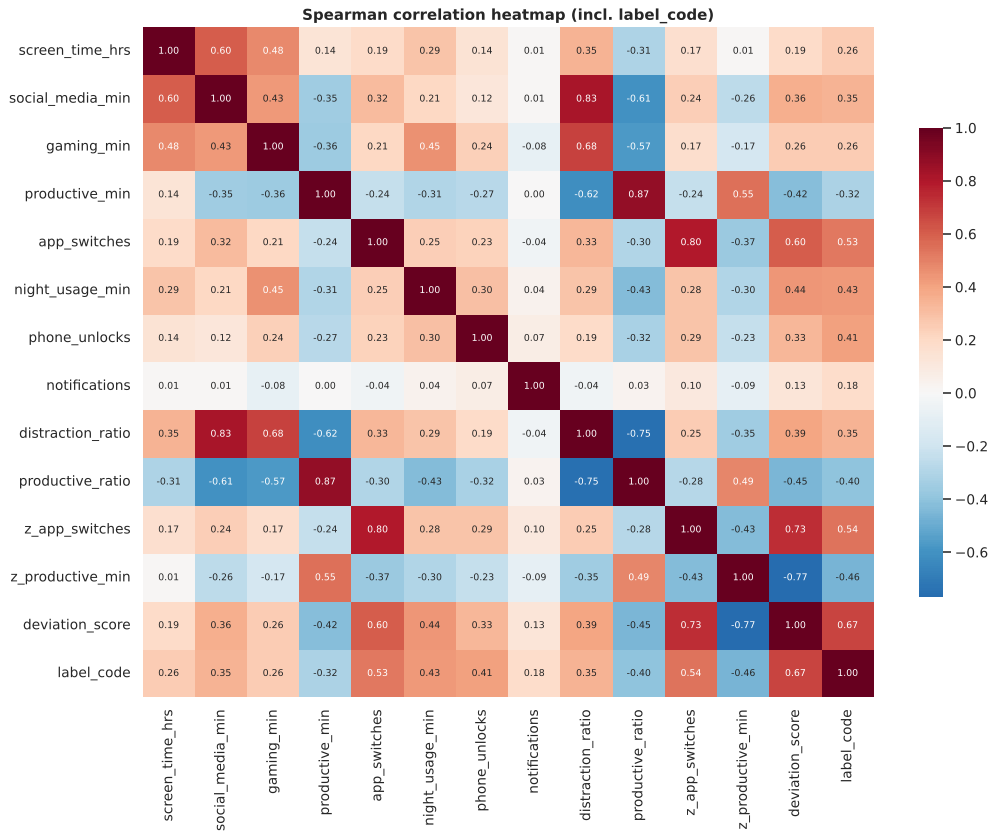

In [23]:
corr_cols = ["screen_time_hrs", "social_media_min", "gaming_min", "productive_min", "app_switches", "night_usage_min",
             "phone_unlocks", "notifications", "distraction_ratio", "productive_ratio", "z_app_switches",
             "z_productive_min", "deviation_score", "label_code"]
fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(feat[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            ax=ax, annot_kws={"size": 7.5}, cbar_kws={"shrink": .7})
ax.set_title("Spearman correlation heatmap (incl. label_code)")
plt.tight_layout(); savefig("10_correlation_heatmap")

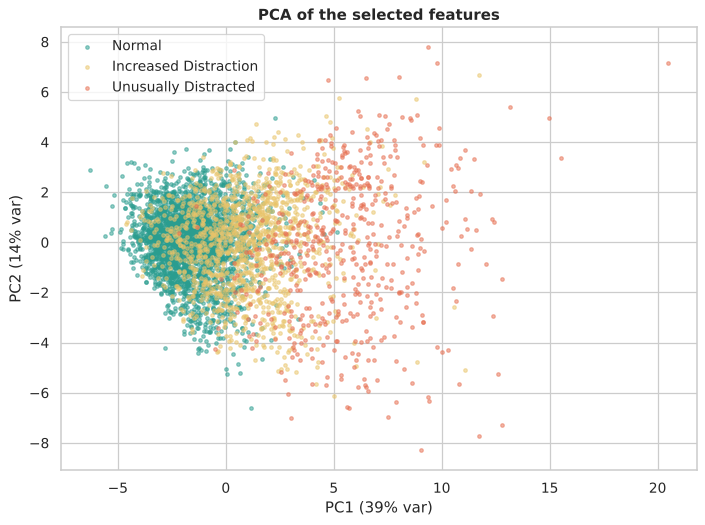

In [24]:
Xp = StandardScaler().fit_transform(feat[FEATURES])
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xp)
pc = pca.transform(Xp)
fig, ax = plt.subplots(figsize=(8, 6))
for i, c in enumerate(CLASSES):
    m = feat["label"] == c
    ax.scatter(pc[m, 0], pc[m, 1], s=8, alpha=.5, color=COLORS[c], label=c)
ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} var)", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} var)",
       title="PCA of the selected features")
ax.legend(); plt.tight_layout(); savefig("11_pca")

## 2.6 Key insights and how they guide model selection
1. **Classes are imbalanced** (≈60 / 29 / 12%). → use stratified evaluation, macro-averaged F1 and `class_weight="balanced"`.
2. **Raw values overlap heavily across users** because personal baselines (median screen time on normal days) range from ~2.5 h to ~7.3 h a day. → models must use **personal deviation (z-score) features**; a single population threshold will fail.
3. **Personal z-scores separate the classes strongly** (largest Kruskal-Wallis effect sizes, highest mutual information). By mutual information, the strongest single signals are deviations in social media, night usage, productive time, gaming and app switching; notifications on their own are weak.
4. **Weekends raise the share of distracted days** (see the day-of-week chart), but the flag `is_weekend` on its own has near-zero mutual information once usage is known: the weekend effect already shows up in the usage values. It is therefore dropped in feature selection, together with `is_student` and `other_min`.
5. **Relationships are partly non-linear and interacting** (e.g. high switching matters more when productive time also drops) and PCA shows overlapping class boundaries. → compare a linear model (Logistic Regression) with tree-based models (Decision Tree, Random Forest) that capture interactions; include unsupervised anomaly detection (Isolation Forest) and clustering (K-Means) because real users rarely label their days.
6. **Distributions are right-skewed with heavy tails.** → robust medians for imputation, scaling inside pipelines, and tree models that are insensitive to monotonic skew.

---
# REVIEW 3 — Model Building and Comparison Analysis
## 3.1 Model selection and justification
| # | Model | Type | Why it fits this problem |
|---|---|---|---|
| 1 | **Z-score statistical baseline** | rule-based | Transparent "how many SDs from my own normal" rule – the simplest possible detector; any ML model must beat it. |
| 2 | **Isolation Forest** | unsupervised anomaly detection | Works without labels; isolates rare, unusual days quickly. |
| 3 | **K-Means clustering** | unsupervised clustering | Discovers natural day-types; evaluated with Silhouette, Davies-Bouldin and Calinski-Harabasz. |
| 4 | **Logistic Regression** | linear probabilistic classifier | Calibrated probabilities, interpretable coefficients, strong baseline for scaled features. |
| 5 | **Decision Tree** | non-linear, rule-based | Human-readable if/then rules; captures interactions. |
| 6 | **Random Forest** | ensemble of trees | Reduces the variance of a single tree; handles non-linearity, skew and interactions; gives feature importance. |

## 3.2 Train / test strategy
* **Chronological hold-out:** train on 8 Jan – 31 Mar, test on 1 – 29 Apr (≈25%). This mimics deployment — we always predict *future* days.
* **Cross-validation on the training set uses `GroupKFold` by user (5 folds):** each fold validates on people the model has never seen, which prevents optimistic scores from a person's correlated days appearing in both train and validation folds.
* Scaling is fitted inside each pipeline on training folds only.

In [25]:
train = feat[feat["date"] < "2024-04-01"].reset_index(drop=True)
test = feat[feat["date"] >= "2024-04-01"].reset_index(drop=True)
X_tr, y_tr, grp_tr = train[FEATURES], train["label_code"].values, train["user_id"].values
X_te, y_te = test[FEATURES], test["label_code"].values
cv = GroupKFold(n_splits=5)
print(f"Train: {len(train)} rows ({train.date.min().date()} → {train.date.max().date()})")
print(f"Test : {len(test)} rows ({test.date.min().date()} → {test.date.max().date()})")
pd.DataFrame({"train %": pd.Series(y_tr).value_counts(normalize=True).sort_index().mul(100).round(1).values,
              "test %": pd.Series(y_te).value_counts(normalize=True).sort_index().mul(100).round(1).values},
             index=CLASSES)

Train: 3360 rows (2024-01-08 → 2024-03-31)
Test : 1160 rows (2024-04-01 → 2024-04-29)


,train %,test %
Normal,57.6,64.1
Increased Distraction,29.7,26.0
Unusually Distracted,12.7,9.9


In [26]:
# ---------- Shared evaluation helper ----------
results, preds, probas = {}, {}, {}

def evaluate(name, y_pred, proba=None, cv_f1=None):
    r = {"Accuracy": accuracy_score(y_te, y_pred),
         "Precision (macro)": precision_score(y_te, y_pred, average="macro", zero_division=0),
         "Recall (macro)": recall_score(y_te, y_pred, average="macro", zero_division=0),
         "F1 (macro)": f1_score(y_te, y_pred, average="macro"),
         "F1 Unusual": f1_score(y_te, y_pred, labels=[2], average="macro"),
         "ROC-AUC (OvR)": roc_auc_score(y_te, proba, multi_class="ovr", average="macro") if proba is not None else np.nan,
         "CV F1 (macro)": cv_f1}
    results[name], preds[name], probas[name] = r, y_pred, proba
    return pd.Series(r).round(3)

def softmax_rows(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def ordinal_proba(score, t1, t2, temp):
    """Turn a 1-D 'how distracted' score into 3 pseudo-probabilities around the two thresholds."""
    return softmax_rows(np.c_[np.zeros_like(score), (score - t1) / temp, 2 * (score - (t1 + t2) / 2) / temp])

### Model 1 — Z-score statistical baseline
Rule: a day is **Unusually Distracted** if its composite deviation score is ≥ 2 SD from the person's own baseline, **Increased Distraction** if ≥ 1 SD, else **Normal**. The thresholds are the textbook 1σ / 2σ rule – nothing is learned from labels.

In [27]:
T1, T2 = 1.0, 2.0
score_te = test["deviation_score"].values
pred_z = np.where(score_te >= T2, 2, np.where(score_te >= T1, 1, 0))
evaluate("Z-score baseline", pred_z, ordinal_proba(score_te, T1, T2, 0.5))

Accuracy             0.716
Precision (macro)    0.664
Recall (macro)       0.522
F1 (macro)           0.540
F1 Unusual           0.554
ROC-AUC (OvR)        0.853
CV F1 (macro)          NaN
dtype: float64

### Model 2 — Isolation Forest (unsupervised anomaly detection)
Trained **without labels** on the training days. The anomaly score is turned into the three classes using the class proportions of the training period (the only label information used), i.e. the top ≈12% most anomalous days → Unusual, the next ≈29% → Increased.

In [28]:
iso_pipe = Pipeline([("sc", StandardScaler()),
                     ("iso", IsolationForest(n_estimators=300, contamination="auto", random_state=RANDOM_STATE))])
Z_ONLY = [f for f in FEATURES if f.startswith(("z_", "dev"))]
iso_pipe.fit(train[Z_ONLY])
iso_tr = -iso_pipe.score_samples(train[Z_ONLY])   # higher = more anomalous
iso_te = -iso_pipe.score_samples(test[Z_ONLY])
prior = pd.Series(y_tr).value_counts(normalize=True).sort_index().values
iT1, iT2 = np.quantile(iso_tr, prior[0]), np.quantile(iso_tr, prior[0] + prior[1])
pred_iso = np.where(iso_te >= iT2, 2, np.where(iso_te >= iT1, 1, 0))
evaluate("Isolation Forest", pred_iso, ordinal_proba(iso_te, iT1, iT2, iso_tr.std() / 2))

Accuracy             0.588
Precision (macro)    0.507
Recall (macro)       0.536
F1 (macro)           0.518
F1 Unusual           0.510
ROC-AUC (OvR)        0.705
CV F1 (macro)          NaN
dtype: float64

### Model 3 — K-Means clustering
Choose *k* with the elbow method, Silhouette, Davies-Bouldin and Calinski-Harabasz scores, then cluster the training days. For the comparison each cluster is mapped to the majority label of its training days (cluster-then-label).

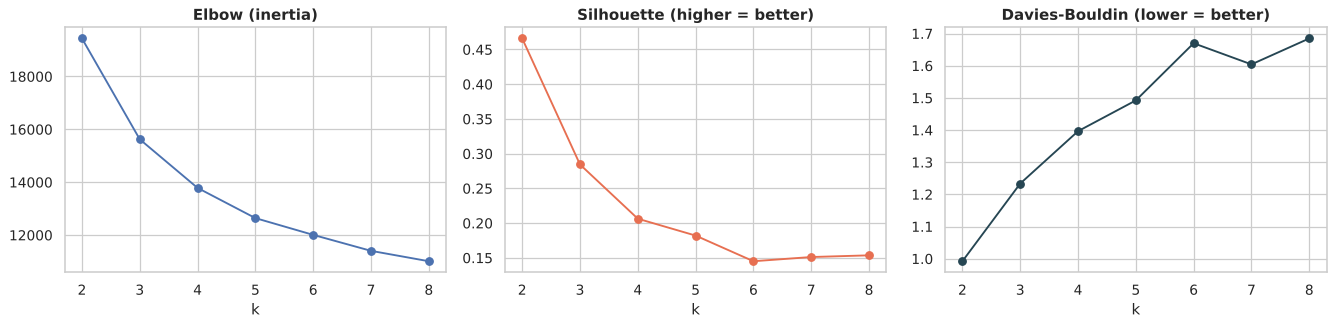

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,19439.365,0.466,0.992,2446.140
3,15623.354,0.284,1.234,1931.328
4,13784.046,0.206,1.397,1608.196
5,12642.519,0.182,1.492,1390.396
6,12008.261,0.145,1.670,1206.153
7,11404.111,0.151,1.604,1087.669
8,11011.021,0.154,1.685,982.371


In [29]:
km_scaler = StandardScaler().fit(train[Z_ONLY])
Xk_tr, Xk_te = km_scaler.transform(train[Z_ONLY]), km_scaler.transform(test[Z_ONLY])
k_rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xk_tr)
    k_rows.append((k, km.inertia_, silhouette_score(Xk_tr, km.labels_, sample_size=2000, random_state=RANDOM_STATE),
                   davies_bouldin_score(Xk_tr, km.labels_), calinski_harabasz_score(Xk_tr, km.labels_)))
k_df = pd.DataFrame(k_rows, columns=["k", "inertia", "silhouette", "davies_bouldin", "calinski_harabasz"]).set_index("k")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
k_df["inertia"].plot(ax=ax[0], marker="o", title="Elbow (inertia)")
k_df["silhouette"].plot(ax=ax[1], marker="o", color="#e76f51", title="Silhouette (higher = better)")
k_df["davies_bouldin"].plot(ax=ax[2], marker="o", color="#264653", title="Davies-Bouldin (lower = better)")
plt.tight_layout(); savefig("12_kmeans_k_selection")
k_df.round(3)

In [30]:
# k = 2 has the best silhouette (it splits "normal" vs "not normal"), but the problem has THREE ordered states,
# and the elbow still bends at k = 3, so k = 3 is used for the 3-class comparison.
K = 3
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(Xk_tr)
cl_tr, cl_te = km.labels_, km.predict(Xk_te)
cluster_to_label = pd.crosstab(cl_tr, y_tr).idxmax(axis=1).to_dict()
pred_km = np.array([cluster_to_label[c] for c in cl_te])
# soft scores: negative distance to each cluster, summed per mapped label
d = -km.transform(Xk_te)
km_scores = np.column_stack([np.max(np.where(np.array([cluster_to_label[c] for c in range(K)]) == lab, d, -1e9), axis=1)
                             for lab in range(3)])
clustering_metrics = {"Silhouette": silhouette_score(Xk_te, cl_te), "Davies-Bouldin": davies_bouldin_score(Xk_te, cl_te),
                      "Calinski-Harabasz": calinski_harabasz_score(Xk_te, cl_te)}
print("Cluster → label mapping:", {k: CLASSES[v] for k, v in cluster_to_label.items()})
print("Clustering quality on test days:", {k: round(v, 3) for k, v in clustering_metrics.items()})
print("Cluster profile (mean z-scores):")
display(pd.DataFrame(km_scaler.inverse_transform(km.cluster_centers_), columns=Z_ONLY).round(2))
evaluate("K-Means", pred_km, softmax_rows(km_scores * 2))

Cluster → label mapping: {0: 'Normal', 1: 'Unusually Distracted', 2: 'Increased Distraction'}
Clustering quality on test days: {'Silhouette': 0.283, 'Davies-Bouldin': 1.247, 'Calinski-Harabasz': 611.807}
Cluster profile (mean z-scores):


,z_screen_time_hrs,z_social_media_min,z_gaming_min,z_productive_min,z_app_switches,z_night_usage_min,z_phone_unlocks,z_distraction_ratio,z_productive_ratio,deviation_score
0,-0.25,-0.62,-0.57,0.67,-0.52,-0.57,-0.41,-0.71,0.74,-0.59
1,1.79,2.95,2.83,-1.43,2.37,2.78,1.94,2.26,-1.87,2.47
2,0.01,0.43,0.42,-0.67,0.38,0.42,0.28,0.63,-0.70,0.46


Accuracy             0.718
Precision (macro)    0.681
Recall (macro)       0.674
F1 (macro)           0.674
F1 Unusual           0.676
ROC-AUC (OvR)        0.847
CV F1 (macro)          NaN
dtype: float64

### Models 4–6 — supervised classifiers (default settings first)

In [31]:
base_models = {
    "Logistic Regression": Pipeline([("sc", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1,
                                            random_state=RANDOM_STATE),
}
for name, model in base_models.items():
    cv_scores = cross_val_score(model, X_tr, y_tr, groups=grp_tr, cv=cv, scoring="f1_macro", n_jobs=-1)
    model.fit(X_tr, y_tr)
    print(f"{name:20s} CV F1 = {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")
    evaluate(name, model.predict(X_te), model.predict_proba(X_te), cv_scores.mean())

Logistic Regression  CV F1 = 0.740 ± 0.039
Decision Tree        CV F1 = 0.622 ± 0.017
Random Forest        CV F1 = 0.760 ± 0.028


## 3.3 Model performance comparison (before tuning)

In [32]:
comparison_before = pd.DataFrame(results).T
comparison_before.style.format("{:.3f}", na_rep="–").background_gradient(cmap="Greens", subset=["F1 (macro)", "ROC-AUC (OvR)"])

,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 Unusual,ROC-AUC (OvR),CV F1 (macro)
Z-score baseline,0.716,0.664,0.522,0.540,0.554,0.853,–
Isolation Forest,0.588,0.507,0.536,0.518,0.510,0.705,–
K-Means,0.718,0.681,0.674,0.674,0.676,0.847,–
Logistic Regression,0.784,0.726,0.779,0.749,0.767,0.890,0.740
Decision Tree,0.704,0.657,0.669,0.662,0.692,0.746,0.622
Random Forest,0.794,0.748,0.760,0.754,0.780,0.895,0.760


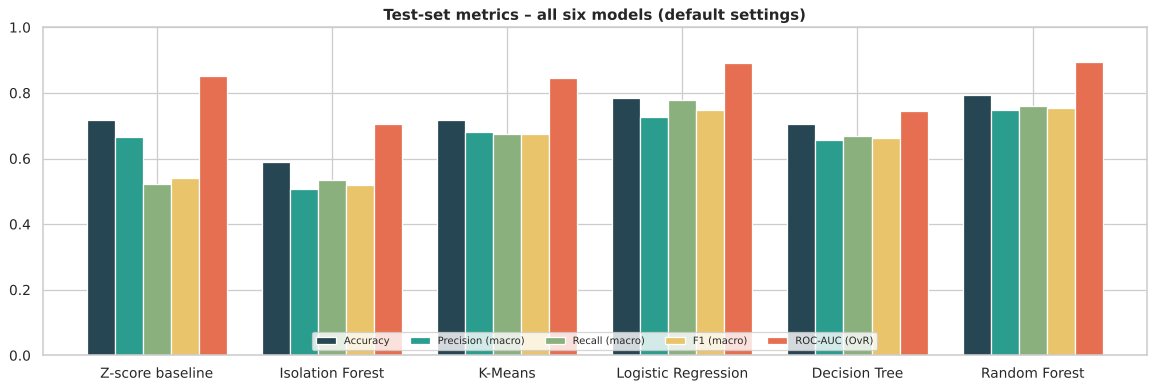

In [33]:
fig, ax = plt.subplots(figsize=(13, 4.5))
comparison_before[["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "ROC-AUC (OvR)"]].plot.bar(
    ax=ax, rot=0, width=.8, color=["#264653", "#2a9d8f", "#8ab17d", "#e9c46a", "#e76f51"])
ax.set_ylim(0, 1); ax.set_title("Test-set metrics – all six models (default settings)"); ax.legend(ncol=5, fontsize=8, loc="lower center")
plt.tight_layout(); savefig("13_model_comparison")

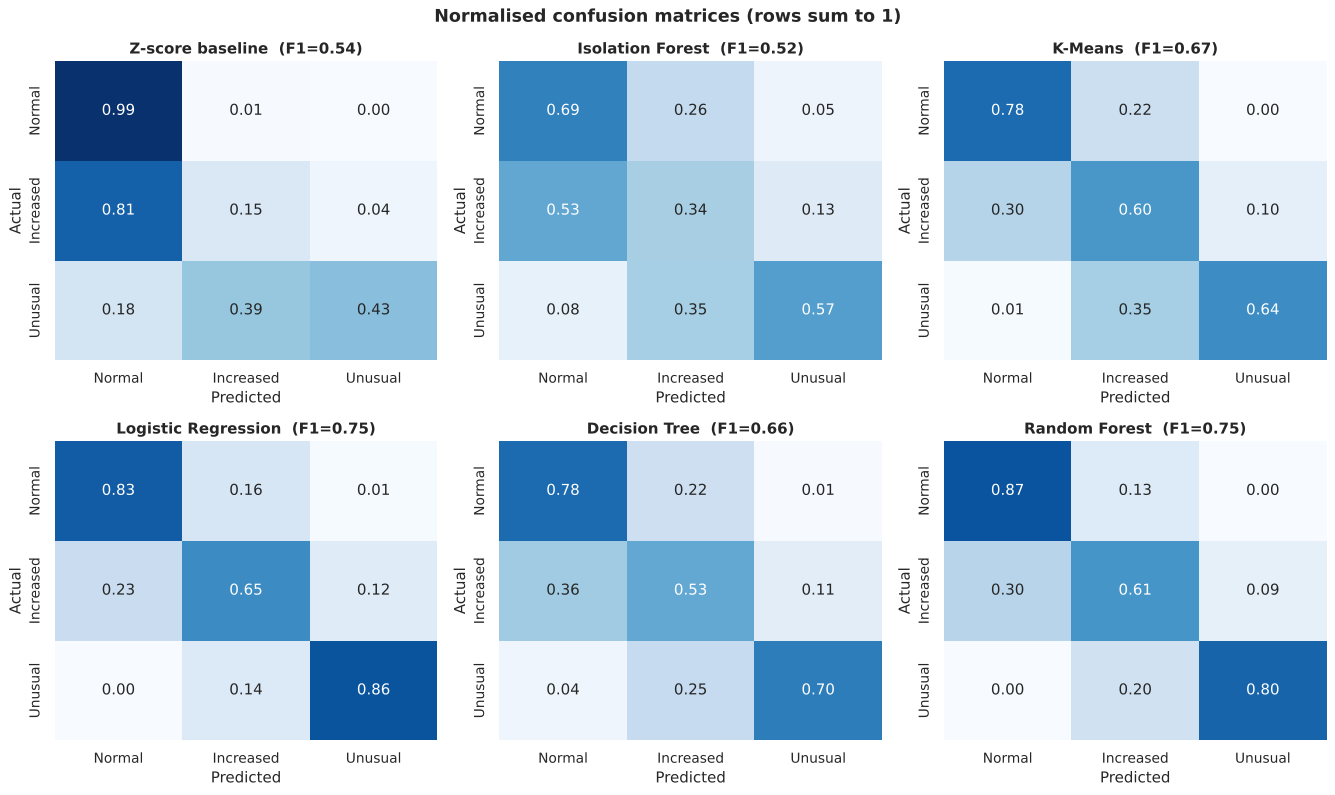

In [34]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
short = ["Normal", "Increased", "Unusual"]
for ax, (name, yp) in zip(axes.ravel(), preds.items()):
    cm = confusion_matrix(y_te, yp, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=short, yticklabels=short)
    ax.set(title=f"{name}  (F1={results[name]['F1 (macro)']:.2f})", xlabel="Predicted", ylabel="Actual")
plt.suptitle("Normalised confusion matrices (rows sum to 1)", fontsize=14, weight="bold")
plt.tight_layout(); savefig("14_confusion_matrices")

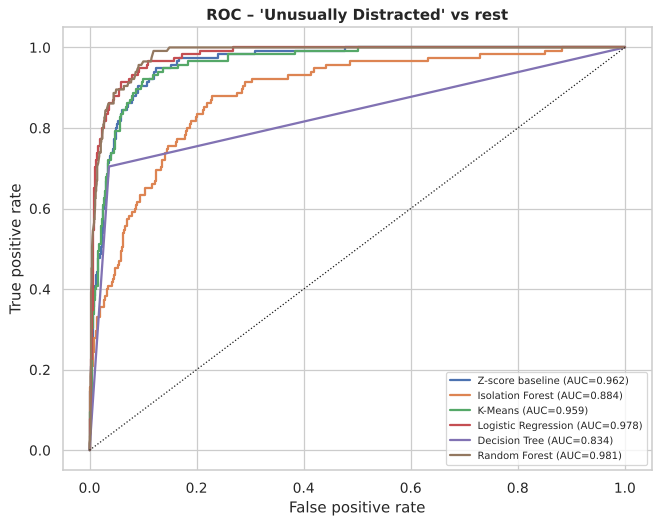

In [35]:
# ROC curves for the clinically most important question: "Is this day Unusually Distracted?" (one-vs-rest)
fig, ax = plt.subplots(figsize=(7.5, 6))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_te == 2, p[:, 2])
    ax.plot(fpr, tpr, lw=1.8, label=f"{name} (AUC={roc_auc_score(y_te == 2, p[:, 2]):.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=1)
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC – 'Unusually Distracted' vs rest")
ax.legend(fontsize=8); plt.tight_layout(); savefig("15_roc_unusual")

**Strengths and limitations of each model**

| Model | Strengths | Limitations seen in the results |
|---|---|---|
| Z-score baseline | No training, fully transparent, needs no labels | One fixed rule for everyone; treats all features equally, so it confuses busy-but-focused days with distracted ones. |
| Isolation Forest | No labels needed; good at flagging the most extreme days | Detects *rarity*, not *distraction direction*: an unusually productive day also looks anomalous; the middle class is hard to separate. |
| K-Means | Reveals natural day-types; useful for profiling | Clusters are spherical and similar-sized, while classes are imbalanced and ordered; the mapping to labels is coarse. |
| Logistic Regression | Stable, calibrated, interpretable coefficients | Linear boundaries only – misses interactions (e.g. switching matters more when productive time drops). |
| Decision Tree | Readable rules, captures interactions | Unpruned tree overfits (high variance) – lowest supervised scores by default. |
| Random Forest | Captures non-linearity and interactions with low variance | Less interpretable (mitigated with feature importance); heavier to deploy. |

## 3.4 Hyperparameter tuning and model optimisation
Grid Search with 5-fold **GroupKFold** cross-validation (by user) on the training set, optimising macro F1.

In [36]:
grids = {
    "Logistic Regression": (base_models["Logistic Regression"],
                            {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10], "clf__class_weight": [None, "balanced"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      {"max_depth": [3, 4, 5, 6, 8, 10], "min_samples_leaf": [5, 10, 20, 40],
                       "criterion": ["gini", "entropy"], "class_weight": [None, "balanced"]}),
    "Random Forest": (RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE),
                      {"n_estimators": [150, 300], "max_depth": [6, 8, 10], "min_samples_leaf": [3, 8],
                       "max_features": ["sqrt", 0.5], "class_weight": ["balanced", "balanced_subsample"]}),
}
tuned, tuning_rows, cv_std = {}, [], {}
for name, (est, grid) in grids.items():
    gs = GridSearchCV(est, grid, scoring="f1_macro", cv=cv, n_jobs=-1).fit(X_tr, y_tr, groups=grp_tr)
    tuned[name] = gs.best_estimator_
    cv_std[f"{name} (tuned)"] = gs.cv_results_["std_test_score"][gs.best_index_]
    yp = gs.best_estimator_.predict(X_te)
    evaluate(f"{name} (tuned)", yp, gs.best_estimator_.predict_proba(X_te), gs.best_score_)
    tuning_rows.append({"Model": name, "Best params": gs.best_params_,
                        "CV F1 before": results[name]["CV F1 (macro)"], "CV F1 after": gs.best_score_,
                        "Test F1 before": results[name]["F1 (macro)"], "Test F1 after": results[f"{name} (tuned)"]["F1 (macro)"]})
tuning = pd.DataFrame(tuning_rows).set_index("Model")
tuning["Δ test F1"] = tuning["Test F1 after"] - tuning["Test F1 before"]
tuning.round(3)

,Best params,CV F1 before,CV F1 after,Test F1 before,Test F1 after,Δ test F1
Model,,,,,,
Logistic Regression,"{'clf__C': 0.03, 'clf__class_weight': None}",0.740,0.752,0.749,0.763,0.014
Decision Tree,"{'class_weight': None, 'criterion': 'gini', 'm...",0.622,0.708,0.662,0.703,0.042
Random Forest,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.760,0.763,0.754,0.750,-0.003


In [37]:
# Unsupervised tuning: search the Z-score thresholds and the Isolation-Forest size on TRAINING data only
best = max(((t1, t2) for t1 in np.arange(0.4, 1.6, 0.1) for t2 in np.arange(1.2, 3.0, 0.1) if t2 > t1 + 0.3),
           key=lambda t: f1_score(y_tr, np.where(train["deviation_score"] >= t[1], 2,
                                                  np.where(train["deviation_score"] >= t[0], 1, 0)), average="macro"))
T1b, T2b = best
pred_zt = np.where(score_te >= T2b, 2, np.where(score_te >= T1b, 1, 0))
evaluate("Z-score baseline (tuned)", pred_zt, ordinal_proba(score_te, T1b, T2b, 0.5))
print(f"Tuned Z thresholds: Increased ≥ {T1b:.1f} SD, Unusual ≥ {T2b:.1f} SD")
tuning.loc["Z-score baseline"] = [{"t1": round(T1b, 1), "t2": round(T2b, 1)}, np.nan, np.nan,
                                  results["Z-score baseline"]["F1 (macro)"], results["Z-score baseline (tuned)"]["F1 (macro)"],
                                  results["Z-score baseline (tuned)"]["F1 (macro)"] - results["Z-score baseline"]["F1 (macro)"]]
tuning.round(3)

Tuned Z thresholds: Increased ≥ 0.4 SD, Unusual ≥ 1.4 SD


,Best params,CV F1 before,CV F1 after,Test F1 before,Test F1 after,Δ test F1
Model,,,,,,
Logistic Regression,"{'clf__C': 0.03, 'clf__class_weight': None}",0.740,0.752,0.749,0.763,0.014
Decision Tree,"{'class_weight': None, 'criterion': 'gini', 'm...",0.622,0.708,0.662,0.703,0.042
Random Forest,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.760,0.763,0.754,0.750,-0.003
Z-score baseline,"{'t1': 0.4, 't2': 1.4}",NaN,NaN,0.540,0.650,0.110


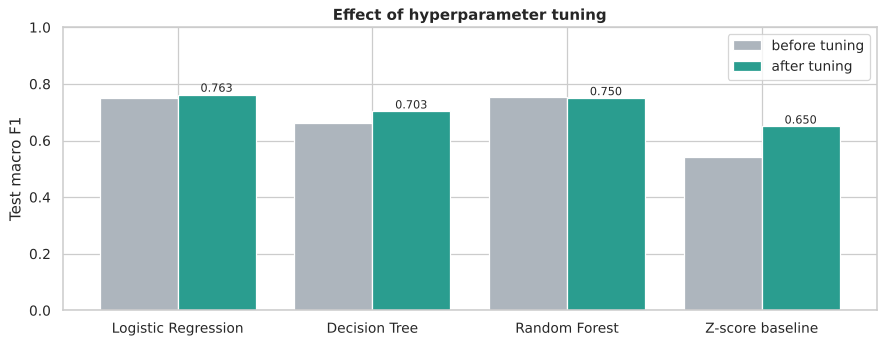

In [38]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(tuning))
ax.bar(x - .2, tuning["Test F1 before"], .4, label="before tuning", color="#adb5bd")
ax.bar(x + .2, tuning["Test F1 after"], .4, label="after tuning", color="#2a9d8f")
for i, (b, a) in enumerate(zip(tuning["Test F1 before"], tuning["Test F1 after"])):
    ax.text(i + .2, a + .01, f"{a:.3f}", ha="center", fontsize=9)
ax.set_xticks(x, tuning.index); ax.set_ylim(0, 1); ax.set_ylabel("Test macro F1")
ax.set_title("Effect of hyperparameter tuning"); ax.legend()
plt.tight_layout(); savefig("16_tuning_effect")

## 3.5 Does the personal baseline really matter? (ablation)
The central hypothesis of the project is that *patterns relative to a person's own normal* matter more than raw totals. The two strongest tuned models are retrained on three feature sets.

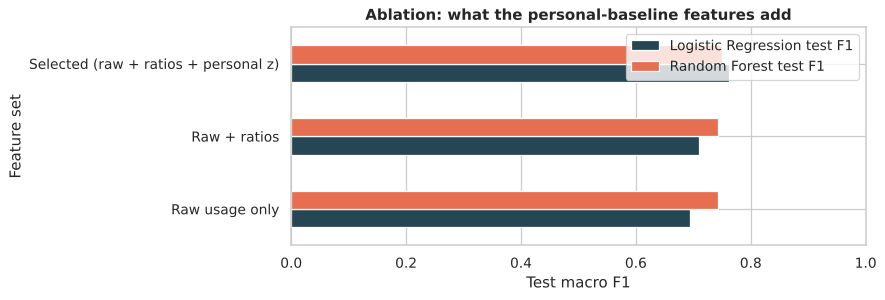

,# features,Logistic Regression test F1,Random Forest test F1
Feature set,,,
Raw usage only,11,0.694,0.742
Raw + ratios,16,0.711,0.743
Selected (raw + ratios + personal z),23,0.763,0.750


In [39]:
abl = {"Raw usage only": RAW_FEATURES, "Raw + ratios": RAW_FEATURES + RATIO_FEATURES,
       "Selected (raw + ratios + personal z)": FEATURES}
abl_rows = []
from sklearn.base import clone
for k, cols in abl.items():
    row = {"Feature set": k, "# features": len(cols)}
    for mname in ["Logistic Regression", "Random Forest"]:
        m = clone(tuned[mname]).fit(train[cols], y_tr)
        row[f"{mname} test F1"] = f1_score(y_te, m.predict(test[cols]), average="macro")
    abl_rows.append(row)
ablation = pd.DataFrame(abl_rows).set_index("Feature set")
ax = ablation.drop(columns="# features").plot.barh(figsize=(10, 3.5), color=["#264653", "#e76f51"])
ax.set_xlim(0, 1); ax.set_xlabel("Test macro F1"); ax.set_title("Ablation: what the personal-baseline features add")
plt.tight_layout(); savefig("17_ablation")
ablation.round(3)

## 3.6 Final model selection
Selection rule (decided before looking at the winner): among the tuned supervised models, count on how many of the seven metrics (six test metrics + cross-validated F1) each model is best; if two models are close, check whether the gap is statistically meaningful and prefer the simpler, more interpretable model when it is not.

In [40]:
final_table = pd.DataFrame(results).T.sort_values("F1 (macro)", ascending=False)
display(final_table.style.format("{:.3f}", na_rep="–").highlight_max(color="#b7e4c7", axis=0))

cands = ["Logistic Regression (tuned)", "Decision Tree (tuned)", "Random Forest (tuned)"]
metric_cols = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "F1 Unusual", "ROC-AUC (OvR)", "CV F1 (macro)"]
ct = final_table.loc[cands, metric_cols]
wins = (ct == ct.max()).sum(axis=1).sort_values(ascending=False)
simplicity = {c: i for i, c in enumerate(cands)}  # LR simplest, RF most complex
best_name = sorted(cands, key=lambda c: (-wins[c], simplicity[c]))[0]
runner = sorted([c for c in cands if c != best_name], key=lambda c: -final_table.loc[c, "F1 (macro)"])[0]
print("Metric wins:", wins.to_dict())
print(f"CV F1 ± std:  " + ",  ".join(f"{c}: {final_table.loc[c, 'CV F1 (macro)']:.3f} ± {cv_std[c]:.3f}" for c in cands))
print(f"\nSelected model: {best_name}   (runner-up: {runner})")

Metric wins: {'Logistic Regression (tuned)': 5, 'Random Forest (tuned)': 2, 'Decision Tree (tuned)': 0}
CV F1 ± std:  Logistic Regression (tuned): 0.752 ± 0.014,  Decision Tree (tuned): 0.708 ± 0.017,  Random Forest (tuned): 0.763 ± 0.032

Selected model: Logistic Regression (tuned)   (runner-up: Random Forest (tuned))


,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 Unusual,ROC-AUC (OvR),CV F1 (macro)
Logistic Regression (tuned),0.812,0.778,0.751,0.763,0.786,0.898,0.752
Random Forest,0.794,0.748,0.760,0.754,0.780,0.895,0.760
Random Forest (tuned),0.793,0.738,0.765,0.750,0.762,0.893,0.763
Logistic Regression,0.784,0.726,0.779,0.749,0.767,0.890,0.740
Decision Tree (tuned),0.761,0.702,0.705,0.703,0.712,0.858,0.708
K-Means,0.718,0.681,0.674,0.674,0.676,0.847,–
Decision Tree,0.704,0.657,0.669,0.662,0.692,0.746,0.622
Z-score baseline (tuned),0.754,0.689,0.637,0.650,0.667,0.855,–
Z-score baseline,0.716,0.664,0.522,0.540,0.554,0.853,–
Isolation Forest,0.588,0.507,0.536,0.518,0.510,0.705,–


In [41]:
# Is the winner significantly different from the runner-up? McNemar test + bootstrap CI on paired test predictions
a, b = preds[best_name] == y_te, preds[runner] == y_te
n01, n10 = int((a & ~b).sum()), int((~a & b).sum())
mcnemar_p = stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
print(f"{best_name} right & {runner} wrong: {n01} days;  opposite: {n10} days;  McNemar p = {mcnemar_p:.3f}")
rng = np.random.default_rng(0)
diffs = []
for _ in range(1000):
    i = rng.integers(0, len(y_te), len(y_te))
    diffs.append(f1_score(y_te[i], preds[best_name][i], average="macro") - f1_score(y_te[i], preds[runner][i], average="macro"))
print(f"Macro-F1 difference: {np.mean(diffs):+.3f}  (95% bootstrap CI {np.percentile(diffs, 2.5):+.3f} to {np.percentile(diffs, 97.5):+.3f})")
gap_vs_baseline = results[best_name]["F1 (macro)"] - results["Z-score baseline"]["F1 (macro)"]
print(f"Improvement over the Z-score statistical baseline: {gap_vs_baseline:+.3f} macro-F1")

Logistic Regression (tuned) right & Random Forest (tuned) wrong: 75 days;  opposite: 53 days;  McNemar p = 0.063
Macro-F1 difference: +0.012  (95% bootstrap CI -0.015 to +0.042)
Improvement over the Z-score statistical baseline: +0.222 macro-F1


In [42]:
final_model = tuned[best_name.replace(" (tuned)", "")]
FINAL_NAME = best_name
print(classification_report(y_te, final_model.predict(X_te), target_names=CLASSES, digits=3))

                       precision    recall  f1-score   support

               Normal      0.861     0.918     0.889       743
Increased Distraction      0.664     0.570     0.613       302
 Unusually Distracted      0.807     0.765     0.786       115

             accuracy                          0.812      1160
            macro avg      0.778     0.751     0.763      1160
         weighted avg      0.804     0.812     0.807      1160



Share of importance from personal-baseline features: 27%


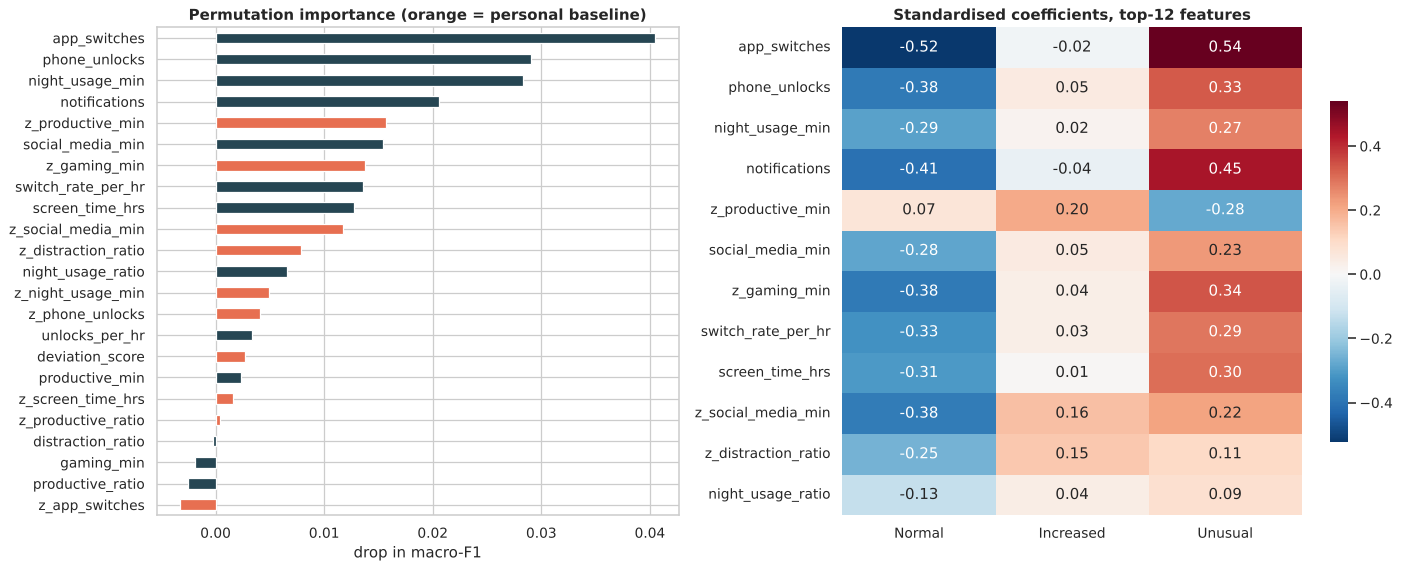

In [43]:
# Interpretation 1: model-agnostic permutation importance (drop in test macro-F1 when a feature is shuffled)
from sklearn.inspection import permutation_importance
pi = permutation_importance(final_model, X_te, y_te, scoring="f1_macro", n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1, 1.1]})
imp.plot.barh(ax=ax[0], color=["#e76f51" if i.startswith(("z_", "dev")) else "#264653" for i in imp.index])
ax[0].set_title("Permutation importance (orange = personal baseline)")
ax[0].set_xlabel("drop in macro-F1")
# Interpretation 2: standardised coefficients (log-odds per 1 SD) when the final model is linear
if hasattr(final_model, "named_steps"):
    coef = pd.DataFrame(final_model.named_steps["clf"].coef_.T, index=FEATURES, columns=["Normal", "Increased", "Unusual"])
    coef = coef.loc[imp.index[::-1][:12]]
    sns.heatmap(coef, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1], cbar_kws={"shrink": .7})
    ax[1].set_title("Standardised coefficients, top-12 features")
else:
    ax[1].axis("off")
plt.tight_layout(); savefig("18_interpretation")
share_z = imp[[f for f in imp.index if f.startswith(("z_", "dev"))]].clip(lower=0).sum() / imp.clip(lower=0).sum()
print(f"Share of importance from personal-baseline features: {share_z:.0%}")

In [44]:
# Error analysis: where does the final model still make mistakes?
test_out = test.assign(pred=final_model.predict(X_te))
err = test_out[test_out.pred != test_out.label_code]
print(f"Errors: {len(err)} of {len(test_out)} test days ({len(err) / len(test_out):.1%})")
adj = int((abs(err.pred - err.label_code) == 1).sum())
print(f"Errors between ADJACENT classes: {adj} of {len(err)} ({adj / len(err):.1%})")
print("Normal days wrongly called 'Unusual' (false alarms of the worst kind):",
      int(((test_out.label_code == 0) & (test_out.pred == 2)).sum()))
pd.crosstab(err["label"], err["pred"].map(dict(enumerate(CLASSES))), rownames=["actual"], colnames=["predicted"])

Errors: 218 of 1160 test days (18.8%)
Errors between ADJACENT classes: 217 of 218 (99.5%)
Normal days wrongly called 'Unusual' (false alarms of the worst kind): 1


predicted,Increased Distraction,Normal,Unusually Distracted
actual,,,
Increased Distraction,0,110,20
Normal,60,0,1
Unusually Distracted,27,0,0


## 3.7 Save the model and export it for the web app

In [45]:
import pickle

with open(MODELS / "final_model.pkl", "wb") as f:
    pickle.dump({"model": final_model, "name": FINAL_NAME, "features": FEATURES, "classes": CLASSES,
                 "baseline_window": WINDOW, "min_days": MIN_DAYS}, f)

if hasattr(final_model, "named_steps"):  # Logistic Regression pipeline
    sc, clf = final_model.named_steps["sc"], final_model.named_steps["clf"]
    export = {"type": "logreg", "mean": sc.mean_.round(6).tolist(), "scale": sc.scale_.round(6).tolist(),
              "coef": clf.coef_.round(6).tolist(), "intercept": clf.intercept_.round(6).tolist()}
else:  # tree ensemble
    def export_tree(t):
        tr = t.tree_
        v = tr.value[:, 0, :] / tr.value[:, 0, :].sum(axis=1, keepdims=True)
        return {"f": tr.feature.tolist(), "t": tr.threshold.round(5).tolist(), "l": tr.children_left.tolist(),
                "r": tr.children_right.tolist(), "v": v.round(4).tolist()}
    export = {"type": "forest", "trees": [export_tree(e) for e in final_model.estimators_]}
export.update({"name": FINAL_NAME, "features": FEATURES, "classes": CLASSES, "window": WINDOW, "min_days": MIN_DAYS})
with open(APP / "model.json", "w") as f:
    json.dump(export, f, separators=(",", ":"))
print(f"Exported {FINAL_NAME} -> app/model.json ({(APP / 'model.json').stat().st_size / 1e3:.1f} kB)")

Exported Logistic Regression (tuned) -> app/model.json (1.7 kB)


In [46]:
# Data for the dashboard: EDA summaries, comparison tables and real user histories for the live demo
def r3(x):
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else round(float(x), 3)

hist_cols = ["screen_time_hrs", "social_media_min", "gaming_min", "productive_min", "other_min", "app_switches",
             "night_usage_min", "phone_unlocks", "notifications"]
demo_users = ["U003", "U017", "U029"]
demo, parity = {}, []
for u in demo_users:
    ud = df[df.user_id == u].reset_index(drop=True)
    start = ud.index[ud.date == "2024-04-15"][0]
    h = ud.iloc[start - WINDOW:start]
    nxt = ud.iloc[start:start + 5]
    demo[u] = {"type": ud.user_type.iloc[0], "history": h[hist_cols].round(2).to_dict("list"),
               "next_days": nxt[hist_cols + ["is_weekend", "label"]].assign(date=nxt.date.dt.strftime("%a %d %b")).to_dict("records")}
    # Python predictions for the same 5 days (the browser must reproduce them using the 14-day rolling window)
    f_rows = feat[(feat.user_id == u) & (feat.date.isin(nxt.date))]
    parity += [{"user": u, "date": d.strftime("%a %d %b"), "proba": [round(float(p), 4) for p in pr]}
               for d, pr in zip(f_rows.date, final_model.predict_proba(f_rows[FEATURES]))]
with open(MODELS / "parity_check.json", "w") as f:
    json.dump(parity, f, indent=1)

dash = {
    "dataset": {"raw_rows": int(len(raw)), "raw_cols": int(raw.shape[1]), "clean_rows": int(len(df)),
                "users": int(df.user_id.nunique()), "days": int(df.date.nunique()), "model_rows": int(len(feat)),
                "train_rows": int(len(train)), "test_rows": int(len(test)), "n_features": len(FEATURES)},
    "issues": [[a, b, int(c)] for a, b, c in issue_table[["Issue", "Column", "Rows affected"]].values],
    "cleaning": [[a, int(b)] for a, b in log],
    "class_counts": df["label"].value_counts().reindex(CLASSES).astype(int).tolist(),
    "weekly_pct": {c: weekly_pct[c].round(1).tolist() for c in CLASSES},
    "box_raw": {c: {k: feat.loc[feat.label == k, c].quantile([.1, .25, .5, .75, .9]).round(2).tolist() for k in CLASSES}
                for c in ["app_switches", "productive_min", "social_media_min", "night_usage_min"]},
    "box_z": {c: {k: feat.loc[feat.label == k, c].quantile([.1, .25, .5, .75, .9]).round(2).tolist() for k in CLASSES}
              for c in ["z_app_switches", "z_productive_min", "z_social_media_min", "z_night_usage_min"]},
    "baselines": normal_days.groupby("user_id")["screen_time_hrs"].median().sort_values().round(2).to_dict(),
    "mutual_info": mi.round(3).to_dict(),
    "comparison": {k: {m: r3(v) for m, v in r.items()} for k, r in results.items()},
    "confusion": {k: confusion_matrix(y_te, v).tolist() for k, v in preds.items()},
    "tuning": [[i, str(r["Best params"]), r3(r["Test F1 before"]), r3(r["Test F1 after"])] for i, r in tuning.iterrows()],
    "ablation": [[i] + [r3(v) for v in r.values] for i, r in ablation.iterrows()],
    "clustering": {k: r3(v) for k, v in clustering_metrics.items()},
    "k_selection": k_df.reset_index().round(3).values.tolist(),
    "importance": imp.sort_values(ascending=False).round(4).to_dict(),
    "final": FINAL_NAME, "runner_up": runner, "mcnemar_p": r3(mcnemar_p),
    "f1_diff_ci": [r3(np.percentile(diffs, 2.5)), r3(np.percentile(diffs, 97.5))],
    "cv_std": {k: r3(v) for k, v in cv_std.items()},
    "user_cv": {c: r3((df.groupby("user_id")[c].std() / df.groupby("user_id")[c].mean()).median()) for c in hist_cols},
    "demo": demo,
}
with open(APP / "dashboard_data.json", "w") as f:
    json.dump(dash, f, separators=(",", ":"), default=str)
print("Saved app/dashboard_data.json and models/parity_check.json")

Saved app/dashboard_data.json and models/parity_check.json


## 3.8 Conclusions
**Final model: tuned Logistic Regression** (`C = 0.03`) on raw usage, activity ratios and personal-baseline z-scores.

| Evidence | Value |
|---|---|
| Test accuracy / macro-F1 | **0.812 / 0.763** – best of all 10 model variants |
| F1 for *Unusually Distracted* / ROC-AUC (OvR) | **0.786 / 0.898** – best |
| Metric wins among tuned supervised models | LR 5 of 7, RF 2 of 7, DT 0 of 7 |
| Gain over the Z-score statistical baseline | +0.22 macro-F1 (default 1σ/2σ rule), +0.11 (tuned rule) |
| vs runner-up Random Forest | +0.012 test F1 (95% CI −0.015 to +0.042), McNemar p = 0.063; CV F1 0.752 ± 0.014 vs 0.763 ± 0.032 |

**Why it is chosen over the Random Forest.** The two are statistically tied: RF is marginally ahead in cross-validation, LR on the hold-out test month, and neither gap exceeds the noise. With equal accuracy the simpler model wins: Logistic Regression is more stable across unseen users (half the fold-to-fold spread), gives calibrated probabilities, has coefficients a user can read ("+1 SD of app switching raises the odds of an *Unusual* day by …"), and exports to a 1.7 kB file that runs instantly in the browser.

**Why it outperforms the other approaches.**
* *Z-score rule:* weighs every signal equally with one fixed threshold; LR **learns** how much each deviation matters (switching and productive-time drops matter far more than total screen time).
* *Isolation Forest / K-Means:* find *unusual* days but not the *direction* — an unusually productive day looks just as anomalous as a distracted one; the unsupervised methods also cannot place the middle class well.
* *Decision Tree:* a single tree has high variance; even tuned it trails by 0.06 F1.
* *Random Forest:* the ablation shows the key mechanism — once behaviour is expressed as **deviation from the person's own baseline**, the class boundary becomes close to linear. LR gains +0.069 F1 from the ratio and z-score features (0.694 → 0.763), while RF's extra flexibility adds variance rather than accuracy.

**What drives the predictions:** permutation importance ranks app switches, phone unlocks, night usage and notifications highest, followed by the personal deviations in productive time and gaming. Notifications are weak on their own (low mutual information) but help in combination with the other signals. Because the raw and z-score versions of a signal share information, shuffling one at a time understates the z-scores; the ablation in 3.5 is the clearer test of their value.

**Remaining errors:** 18.8% of test days are misclassified and all but one are between **adjacent** classes (mostly *Increased ↔ Normal*), which is expected with ~7% noisy self-reported labels and the gradual nature of distraction. Only one Normal day was called *Unusual*.

**Limitations and future work:** simulated data (validate on real, consented logs), a 7-day warm-up before a personal baseline exists, and self-reported labels. Next steps: sequence models over consecutive days, per-user threshold calibration, on-device inference for privacy.

**Product:** the model is exported to `app/model.json` and served by the interactive web app (`app/index.html`), which rebuilds the 14-day personal baseline and scores a day directly in the browser.